# Demanda de transporte público en el AMBA (SUBE, 2020–2026): hitos, causalidad y pronóstico

Trabajo final de Series Temporales (Maestría en Ciencia de Datos).

> **Esta versión reemplaza al notebook original.** El original planteaba dos hipótesis con "veredictos" y comparaba los modelos en una única ventana de 90 días, con métricas infladas por fuga de información. Qué cambió y por qué: `docs/registro_de_cambios.md`. Lectura detallada de cada resultado, con sus límites: `docs/interpretacion_resultados.md`.
>
> **Cómo está armado.** Los análisis pesados (evaluación con origen móvil, panel, control sintético) corren con los scripts de `scripts/` y guardan sus resultados en `resultados/`. Este notebook corre en vivo lo liviano (exploración, estacionariedad, descomposición) y **lee y muestra** los resultados guardados, de modo que se ejecuta de punta a punta en pocos minutos.

## Índice

1. Introducción y motivación
2. Preguntas de trabajo
3. Datos y calidad
4. Exploración de la serie
5. **P-1.** Demanda ante los hitos: precio, calendario y causalidad
6. **P-2.** Qué método pronostica mejor y por qué (incluye cómo pronostican los métodos los hitos de P-1)
7. Discusión y conclusiones
8. Reproducibilidad y referencias

## 1. Introducción y motivación

El AMBA es uno de los sistemas de transporte público más grandes de América Latina: millones de viajes diarios en colectivo, tren y subte, todos pagados con la misma tarjeta SUBE. Entre 2020 y 2026 la demanda pasó por una pandemia, un cambio fuerte en los hábitos de trabajo, una secuencia de saltos tarifarios y, en el medio, paros, elecciones y feriados que alteran un día cualquiera.

Dos preguntas prácticas ordenan este trabajo:

- **Entender.** Cuando algo cambia (el precio, el calendario, un paro), ¿cuánto se mueve la demanda y podemos atribuir ese movimiento a la causa, o solo lo observamos al mismo tiempo?
- **Anticipar.** Para planificar el servicio, ¿qué método de pronóstico funciona mejor con la demanda diaria y por qué?

Son preguntas distintas y piden herramientas distintas. Entender una causa exige aislar el efecto de lo demás (un contrafactual: qué habría pasado sin el cambio). Pronosticar exige un modelo que acierte, aunque no explique. El trabajo trata las dos por separado y muestra cuándo conviene cada enfoque.

## 2. Preguntas de trabajo

**P-1. ¿Cómo se comportó la demanda alrededor de los hitos, y por qué?** Hitos: pandemia (solo descriptivo), saltos tarifarios, feriados, paros y elecciones. El "por qué" se aborda con herramientas de causalidad (contrafactual con controles, control sintético, Granger) y se declara qué supuestos hacen falta en cada caso.

**P-2. ¿Qué métodos pronostican mejor la demanda diaria, y por qué?** Se comparan cuatro métodos (Naive estacional, SARIMAX, Prophet y Gradient Boosting) con evaluación de origen móvil, prueba de significancia y variantes que explican *por qué* uno gana.

**Qué cambió respecto del trabajo original.** (1) Las Hipótesis 1 y 2 se reemplazaron por estas preguntas, porque los "veredictos" no eran sostenibles con los datos. (2) Se descartó medir la "recuperación contra el nivel pre-COVID": solo hay enero y febrero de 2020 como base, que además es temporada baja. (3) Se corrigió una fuga de información en dos de los cuatro modelos. (4) La comparación pasó de una ventana de 90 días a 42 cortes sucesivos.

In [1]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.width", 200, "display.max_columns", 30)

BASE = Path("..") if (Path("..") / "data").exists() else Path(".")
TAB, FIG, PROC = BASE / "resultados" / "tablas", BASE / "resultados" / "figuras", BASE / "data" / "procesado"


def tabla(nombre, filtro=None, cols=None, decimales=3, **pivot):
    """Muestra una tabla guardada en resultados/tablas (opcionalmente filtrada o pivotada)."""
    d = pd.read_csv(TAB / f"{nombre}.csv")
    if filtro:
        d = d.query(filtro, engine="python")
    if pivot:
        d = d.pivot(**pivot)
    if cols:
        d = d[cols]
    display(d.round(decimales))


def figura(nombre, ancho=11):
    """Muestra una figura guardada en resultados/figuras."""
    img = mpimg.imread(FIG / nombre)
    alto = ancho * img.shape[0] / img.shape[1]
    plt.figure(figsize=(ancho, alto)); plt.imshow(img); plt.axis("off"); plt.tight_layout(); plt.show()

## 3. Datos y calidad

**Fuente.** Registros de validadoras de la red SUBE publicados por la Secretaría de Transporte de la Nación (datos.transporte.gob.ar). La unidad es la cantidad de **tarjetas distintas usadas por día** en cada modo, no la cantidad de viajes. El total nunca supera la suma de los modos, lo que sugiere que deduplica tarjetas que usan más de un modo (inferencia: el portal no lo documenta).

**Huecos.** Faltan 62 días, dos meses completos: **agosto de 2022** y **enero de 2024**. El portal publica además las **transacciones** diarias por línea, sin huecos. Como usuarios y transacciones están muy correlacionados, los usuarios faltantes se reconstruyen como transacciones × la razón usuarios/transacciones de los días vecinos. Se probó antes sobre bloques de 31 días ocultos de la propia serie: el sesgo mediano es de −0,4% a −0,1% y, en meses de vacaciones, el error es de 1,6% a 3,2% contra 12% a 21% de la interpolación simple.

**Octubre de 2026** es preliminar (sus transacciones son 100% preliminares) y queda afuera de las evaluaciones.

### Fuentes de datos externas al dataset de usuarios

Además de la serie de usuarios por día, el trabajo usa otras fuentes. Se listan acá con su rol, porque algunas condicionan cómo se leen los resultados de P-1.

| Fuente | Organismo | Qué aporta y dónde se usa |
|---|---|---|
| **Transacciones SUBE por fecha** (`dat-ab-usos-AAAA.csv`) | Secretaría de Transporte de la Nación (datos.transporte.gob.ar) | Cantidad de usos (transacciones) por día, modo, jurisdicción y línea, sin los huecos de la serie de usuarios. Se usa para reconstruir los 62 días faltantes y como medida de demanda en P-1. Incluye las **ciudades del interior** (fuera del AMBA, también con SUBE) que sirven de **donantes** del control sintético del colectivo. |
| **Tarifas** (`hitos_tarifas.csv`, `serie_tarifas_diaria.csv`) | Boletín Oficial nacional y de la Ciudad de Buenos Aires (resoluciones) y prensa | Tarifa mínima con SUBE de cada modo y jurisdicción. Elaboración propia: cada fila indica la fuente y su estado de verificación (norma, prensa de dos o más medios, una sola fuente, inferida). |
| **IPC nacional, nivel general** | INDEC | Deflactor de las tarifas (tarifa real). |
| **RIPTE** (remuneración imponible promedio de los trabajadores estables) | Secretaría de Trabajo, Empleo y Seguridad Social, vía datos.gob.ar | Salario como control del poder de compra (salario real = RIPTE / IPC) y para expresar la tarifa en salarios. Es un salario formal, nacional y mensual. |
| **Encuesta Anual de Hogares (EAH)** de la Ciudad de Buenos Aires | Dirección General de Estadística y Censos (IDECBA), Ciudad de Buenos Aires | Ingreso per cápita familiar medio por comuna, 2022–2025. Se usa solo para ordenar las líneas de subte por ingreso de la zona que atraviesan (contraste de ingreso del apartado 5.5). |
| **Comunas, estaciones y red de subte** (GeoJSON) | BA Data, Gobierno de la Ciudad de Buenos Aires | Ubicar cada estación en una comuna y, con ello, cada línea. |
| **Paros y elecciones** (`hitos_paros_elecciones.csv`) | Elaboración propia a partir de prensa | Fecha, descripción, modos afectados según las fuentes y estado de verificación de cada evento (confirmado con dos o más fuentes, con discrepancias, inferido del dato). |
| **Feriados nacionales** | Paquete `holidays` de Python (calendario de Argentina) | Calendario conocido de antemano, usado en los modelos y para excluir días en P-1. |

**Alcance.** La EAH cubre solo la Ciudad de Buenos Aires, no el conurbano: el índice de ingreso describe la zona de las estaciones, no necesariamente a quienes viajan. Las tarifas de las ciudades del interior no se pudieron verificar una por una. Los paros y elecciones sin fuente se identificaron por el comportamiento de la demanda, lo que introduce cierta circularidad que se declara en cada fila.

2020-01-01 a 2026-10-29  |  2494 días  |  62 reconstruidos


,total_amba,colectivo_amba,tren_amba,subte_amba
count,1734.0,1734.0,1734.0,1734.0
mean,3061790.0,2852255.0,524984.0,316259.0
std,1040864.0,963113.0,219298.0,148125.0
min,239491.0,236439.0,90.0,1.0
25%,2301636.0,2149058.0,368600.0,183423.0
50%,3396512.0,3142209.0,613814.0,313067.0
75%,3969806.0,3699056.0,701073.0,454234.0
max,4440736.0,4114665.0,826247.0,685562.0


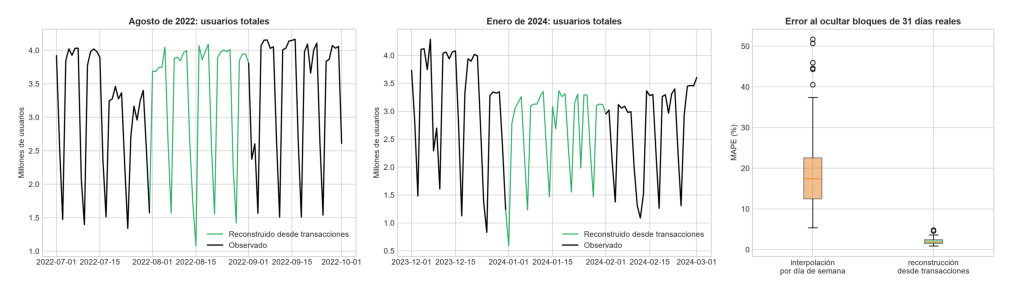

In [2]:
serie = pd.read_csv(PROC / "serie_sube_diaria_reconstruida.csv", parse_dates=["fecha"]).set_index("fecha").asfreq("D")
print(f"{serie.index.min().date()} a {serie.index.max().date()}  |  {len(serie)} días  |  {int(serie.imputado.sum())} reconstruidos")
display(serie.loc["2022-01-01":"2026-09-30", ["total_amba", "colectivo_amba", "tren_amba", "subte_amba"]].describe().round(0))
figura("fig12_reconstruccion_huecos.png")

## 4. Exploración de la serie

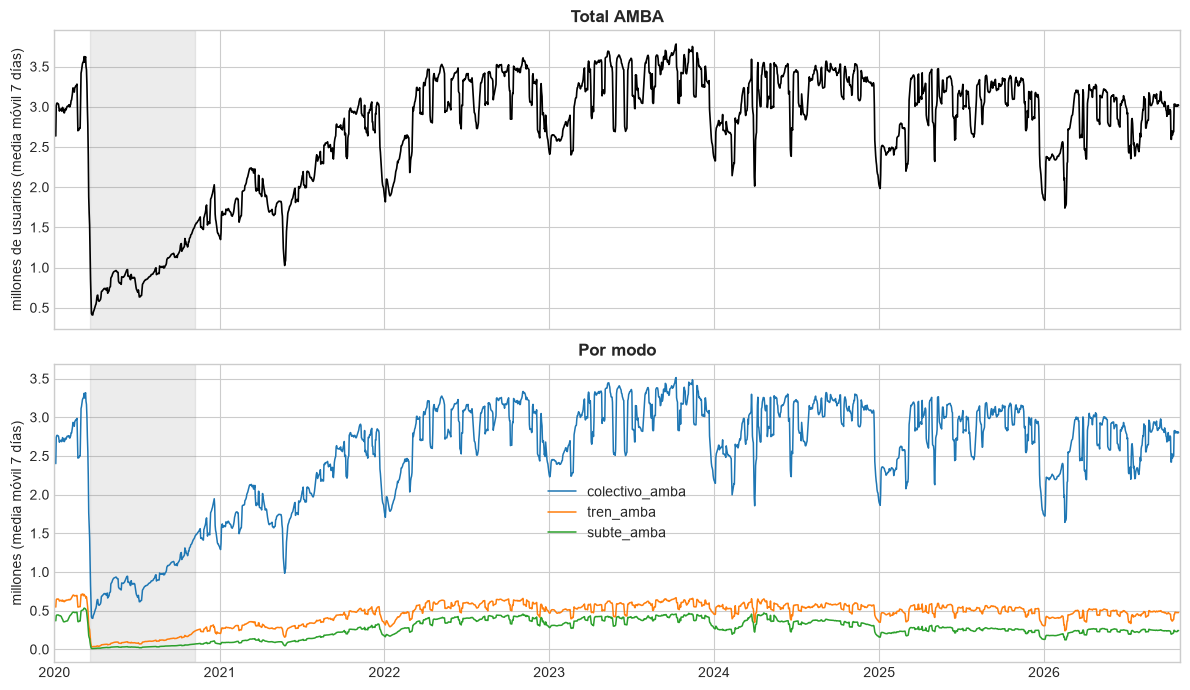

Zona gris: aislamiento estricto de 2020. El COVID se trata como shock descriptivo y queda fuera de los modelos de pronóstico (que usan datos desde 2022).


In [3]:
modos = ["colectivo_amba", "tren_amba", "subte_amba"]
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
(serie["total_amba"] / 1e6).rolling(7, center=True).mean().plot(ax=ax[0], color="k", lw=1.2)
ax[0].set_ylabel("millones de usuarios (media móvil 7 días)"); ax[0].set_title("Total AMBA", fontweight="bold")
(serie[modos] / 1e6).rolling(7, center=True).mean().plot(ax=ax[1], lw=1.1)
ax[1].set_ylabel("millones (media móvil 7 días)"); ax[1].set_title("Por modo", fontweight="bold"); ax[1].set_xlabel("")
for a in ax:
    a.axvspan(pd.Timestamp("2020-03-20"), pd.Timestamp("2020-11-08"), color="grey", alpha=0.15)
plt.tight_layout(); plt.show()
print("Zona gris: aislamiento estricto de 2020. El COVID se trata como shock descriptivo y queda fuera de los modelos de pronóstico (que usan datos desde 2022).")

**Estacionalidad semanal y anual.** La demanda tiene un ciclo semanal muy marcado (días hábiles muy por encima de sábados y domingos) y una estacionalidad anual (vacaciones de invierno y verano). Ambas son las que luego explican gran parte del error de los modelos de pronóstico.

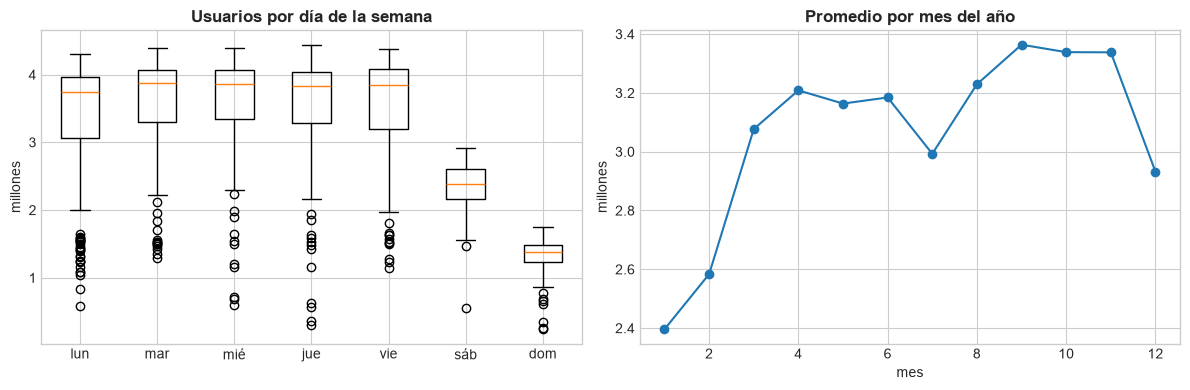

In [4]:
s = serie.loc["2022-01-01":"2026-09-30", "total_amba"] / 1e6
d = pd.DataFrame({"y": s, "dia": s.index.dayofweek, "mes": s.index.month})
nombres = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].boxplot([d.y[d.dia == i] for i in range(7)], tick_labels=nombres); ax[0].set_title("Usuarios por día de la semana", fontweight="bold"); ax[0].set_ylabel("millones")
d.groupby("mes").y.mean().plot(ax=ax[1], marker="o"); ax[1].set_title("Promedio por mes del año", fontweight="bold"); ax[1].set_xlabel("mes"); ax[1].set_ylabel("millones")
plt.tight_layout(); plt.show()

**Estacionariedad (ADF y KPSS).** Una serie es (débilmente) estacionaria si su media, su varianza y su autocovarianza no dependen del tiempo; los modelos ARIMA/SARIMAX la requieren después de las diferencias que se apliquen. Se usan dos pruebas con hipótesis nulas opuestas:

- **ADF** (Dickey-Fuller aumentada): hipótesis nula = la serie tiene una raíz unitaria (no es estacionaria). Un p-valor menor a 0,05 rechaza la nula, es decir, apunta a estacionariedad.
- **KPSS**: hipótesis nula = la serie es estacionaria alrededor de un nivel constante. Un p-valor menor a 0,05 rechaza la nula, es decir, apunta a *no* estacionariedad. (statsmodels acota su p-valor al intervalo 0,01–0,10, por eso se repiten esos valores.)

Se concluye solo cuando las dos coinciden: **estacionaria** si ADF rechaza y KPSS no rechaza; **no estacionaria** si ADF no rechaza y KPSS rechaza; **indefinida** si discrepan. Se aplican a la serie en nivel, a la diferencia estacional de 7 días (resta el mismo día de la semana anterior) y a esa diferencia más una diferencia simple.

Se prueban tres tramos: la serie completa desde 2020 (incluye la pandemia), el período **2022–2026** (sin pandemia: es el período que usan los modelos de pronóstico) y el tramo de **entrenamiento inicial** (enero de 2022 a junio de 2023), el único que se usa para identificar el orden del SARIMAX sin mirar el período de prueba.

In [5]:
from statsmodels.tsa.stattools import adfuller, kpss

completa = serie.loc[:"2026-09-30", "total_amba"] / 1e6


def decision(x):
    x = x.dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pa, pk = adfuller(x, autolag="AIC")[1], kpss(x, regression="c", nlags="auto")[1]
    dec = "estacionaria" if (pa < 0.05 and pk >= 0.05) else ("no estacionaria" if (pa >= 0.05 and pk < 0.05) else "indefinida")
    return {"p ADF": round(pa, 4), "p KPSS": round(pk, 4), "decisión": dec}


tramos = {"2020–2026 (con pandemia)": completa,
          "2022–2026 (sin pandemia)": completa.loc["2022-01-01":],
          "2022 a jun-2023 (entrenamiento inicial)": completa.loc["2022-01-01":"2023-06-30"]}
filas = []
for nombre, x in tramos.items():
    for trans, v in [("nivel", x), ("dif. estacional (7)", x.diff(7)), ("dif. estacional (7) + simple (1)", x.diff(7).diff())]:
        filas.append({"tramo": nombre, "días": len(x), "transformación": trans, **decision(v)})
display(pd.DataFrame(filas).set_index(["tramo", "días", "transformación"]))

p ADF  p KPSS         decisión
tramo                                   días transformación                                                   
2020–2026 (con pandemia)                2465 nivel                             0.2448  0.0100  no estacionaria
                                             dif. estacional (7)               0.0000  0.1000     estacionaria
                                             dif. estacional (7) + simple (1)  0.0000  0.1000     estacionaria
2022–2026 (sin pandemia)                1734 nivel                             0.0001  0.1000     estacionaria
                                             dif. estacional (7)               0.0000  0.1000     estacionaria
                                             dif. estacional (7) + simple (1)  0.0000  0.1000     estacionaria
2022 a jun-2023 (entrenamiento inicial) 546  nivel                             0.0088  0.0159       indefinida
                                             dif. estacional (7)               0.0000  0.1000     estacionaria
                                             dif. estacional (7) + simple (1)  0.0000  0.1000     estacionaria

**Lectura.** Con la serie completa, que incluye la caída y la recuperación de la pandemia, el nivel **no es estacionaria** (ADF no rechaza y KPSS sí rechaza): la media cambia a lo largo del tiempo. Al excluir la pandemia y usar **2022–2026**, ADF y KPSS coinciden en que el nivel es **estacionario**: sin el shock de 2020 y 2021 la serie fluctúa alrededor de un nivel estable (con el ciclo semanal y la estacionalidad anual). En el tramo corto de entrenamiento inicial (2022 a junio de 2023) la decisión es **indefinida**, un resultado que podría deberse a la corta extensión del tramo (546 observaciones). En los tres tramos la diferencia estacional de 7 días deja la serie estacionaria.

**Qué decisión se toma.** Los resultados con la serie completa se conservan como referencia, pero no se usan para modelar porque incluyen un período que queda afuera del análisis. Para el SARIMAX se mantiene **d = 0** y **D = 1 con período 7**: el nivel no necesita diferencia simple (resultado estable al pasar de 2022 a 2026) y la diferencia estacional elimina el ciclo semanal, que las pruebas de raíz unitaria no evalúan (una estacionalidad determinista fuerte no es una raíz unitaria, pero un modelo ARIMA la necesita tratada de alguna manera). Además, las pruebas son sensibles a quiebres de nivel: un resultado de "estacionaria" en 2022–2026 no descarta cambios de nivel puntuales, como la caída del subte de 2024.

**Descomposición (STL).** Separa tendencia, estacionalidad semanal y residuo. El residuo concentra los feriados, los paros y las elecciones: es donde los modelos van a fallar y por eso P-1 los estudia.

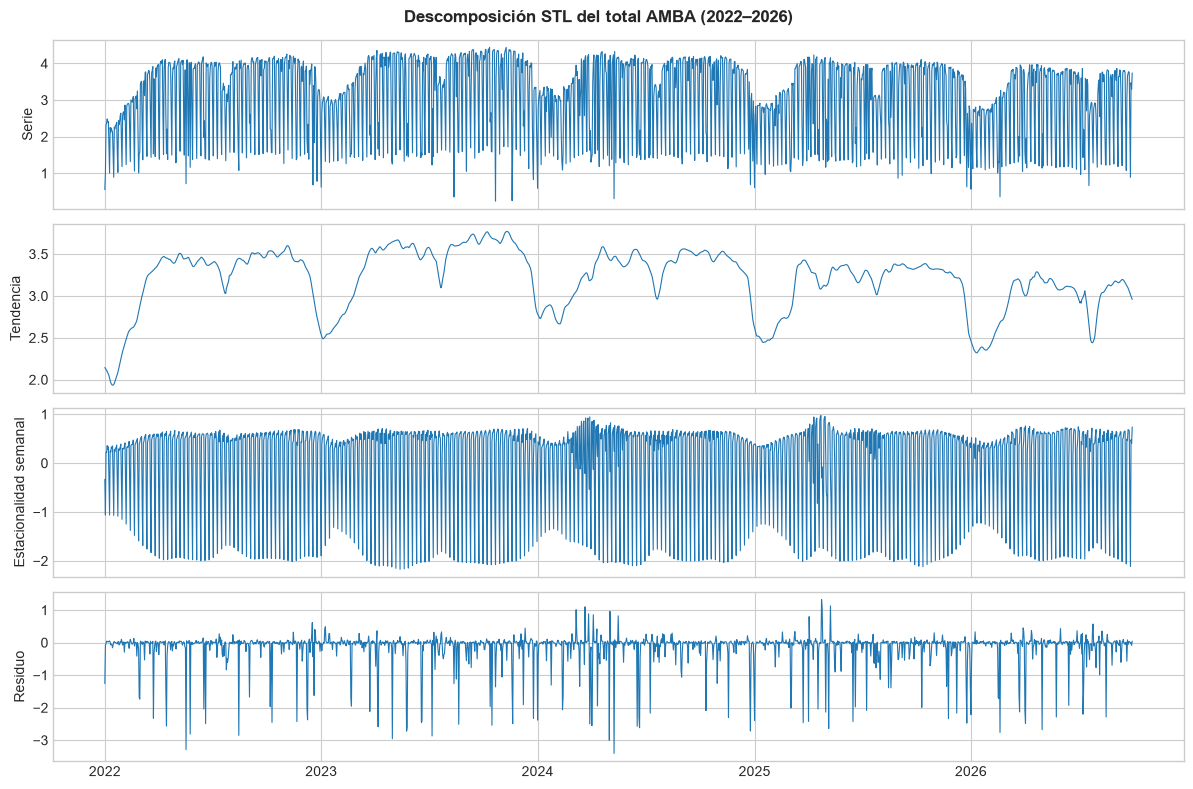

In [6]:
from statsmodels.tsa.seasonal import STL
res = STL(s, period=7, robust=True).fit()
fig, ax = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for a, (nombre, v) in zip(ax, [("Serie", s), ("Tendencia", res.trend), ("Estacionalidad semanal", res.seasonal), ("Residuo", res.resid)]):
    a.plot(v, lw=0.8); a.set_ylabel(nombre)
plt.suptitle("Descomposición STL del total AMBA (2022–2026)", fontweight="bold"); plt.tight_layout(); plt.show()

## 5. P-1. Demanda ante los hitos: precio, calendario y causalidad

**Cómo se entiende "causalidad" en este trabajo.** Dos ideas de la materia:

1. **Granger** pregunta si el pasado de una serie (acá, la tarifa) mejora la predicción de otra (la demanda). Sirve para *predecir*, pero no demuestra que el precio *cause* la demanda ni sirve para intervenir en el sistema. Se usa como evidencia complementaria y se informa con ese límite.
2. **Efecto de una intervención (contrafactual).** Se compara lo ocurrido con lo que *habría* ocurrido sin el cambio, estimado con series de control que no recibieron el tratamiento. Requiere supuestos: que los controles sean comparables y que no haya otros eventos simultáneos propios de lo estudiado. Es lo que hacen el **estudio de eventos con control del año anterior** y el **control sintético** con ciudades del interior.

Ningún diseño de este trabajo es un experimento: todos dependen de supuestos que se declaran junto a cada resultado.

**Términos que se usan en toda la sección.**

- **Salto tarifario:** aumento de la tarifa mínima con SUBE de al menos **10% en un solo cambio** (hay 29 en la serie de 2022 a 2026). Un cambio menor al 10% se llama **ajuste** (en general, ajustes mensuales de alrededor de 5%; hay 76).
- **Salto tarifario grande:** aquel en que la tarifa **se duplica o más**. Hay tres, todos en 2024: colectivo nacional (+251%) y tren (+169%) el 6 de febrero, y subte (+359%) el 17 de mayo. Los demás saltos son **moderados** (de +10% a +40%). El umbral de 10% es el que usa el código para distinguir saltos de ajustes; el de "grande" es una convención de este trabajo para separar los tres aumentos de otro orden de magnitud.
- **Elasticidad precio de la demanda:** ε = variación porcentual de la demanda / variación porcentual del precio. Aquí se calcula como el cambio en el logaritmo de la demanda dividido por el cambio en el logaritmo de la tarifa. Si ε = −0,2, un aumento de 10% de la tarifa se asocia con una caída de 2% de la demanda. Con |ε| < 1 la demanda es **inelástica** (el gasto total sube cuando sube la tarifa); con ε = 0 no reacciona. Como referencia, la literatura internacional reporta elasticidades de corto plazo del orden de −0,3 a −0,4 para el colectivo y de −0,3 para el metro (Balcombe et al., 2004, informe TRL593), con valores de largo plazo más altos en valor absoluto.
- **Tarifa real:** tarifa nominal dividida por el IPC, para descontar la inflación.

### 5.1 Tarifas
La serie de tarifas por modo y jurisdicción se armó con resoluciones oficiales (Boletín Oficial) y, donde no había norma a mano, inferida (cada fila indica su fuente). El primer gráfico muestra las tarifas **nominales** en escala logarítmica; casi todo el crecimiento de 2022 y 2023 es inflación, de modo que el segundo gráfico las corrige.

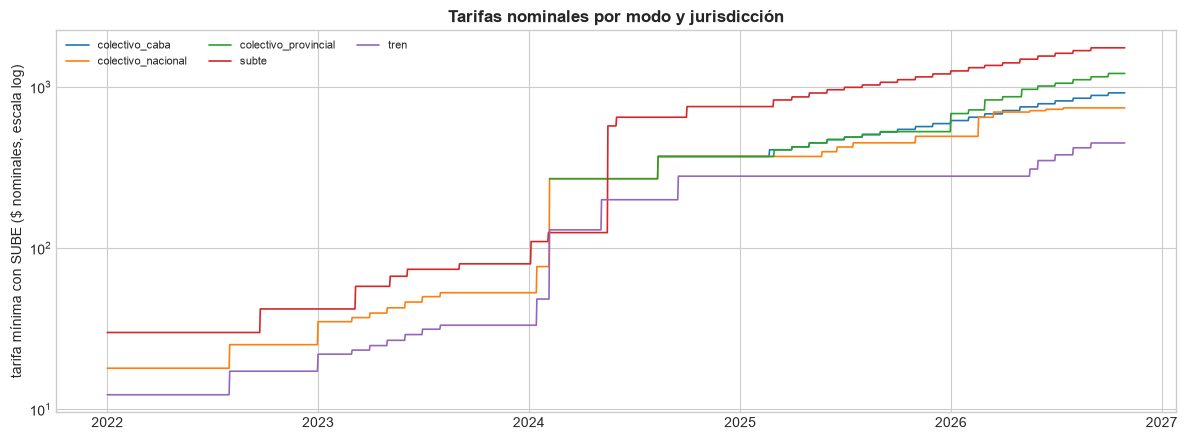

,serie,cambios_con_valor,con_norma_oficial,con_conflicto_entre_fuentes,primer_valor,meses_2024_2026_sin_cambio_registrado
0,colectivo_caba,21,0,1,2024-08-12,13
1,colectivo_nacional,23,6,1,2022-01-01,21
2,colectivo_provincial,19,1,2,2024-02-06,15
3,subte,30,16,1,2022-01-01,9
4,tren,18,6,2,2022-01-01,24


In [7]:
tar = pd.read_csv(BASE / "data" / "hitos" / "serie_tarifas_diaria.csv", parse_dates=["fecha"])
fig, ax = plt.subplots(figsize=(12, 4.5))
for nombre, g in tar.groupby("serie"):
    g = g.dropna(subset=["tarifa"])
    if len(g):
        ax.plot(g.fecha, g.tarifa, label=nombre, lw=1.2)
ax.set_yscale("log"); ax.set_ylabel("tarifa mínima con SUBE ($ nominales, escala log)"); ax.legend(ncol=3, fontsize=8)
ax.set_title("Tarifas nominales por modo y jurisdicción", fontweight="bold"); plt.tight_layout(); plt.show()
tabla("tabla_tarifas_cobertura")

**Tarifa real y tarifa en salarios.** El gráfico siguiente muestra a la izquierda la tarifa **real** (pesos constantes de enero de 2022, deflactada por el IPC nacional) y a la derecha el costo de **40 viajes por mes** (20 días hábiles, ida y vuelta; es un supuesto ilustrativo) como porcentaje del **RIPTE**, una medida del salario formal promedio. Sirve para ver cuánto del salario representa moverse en cada modo.

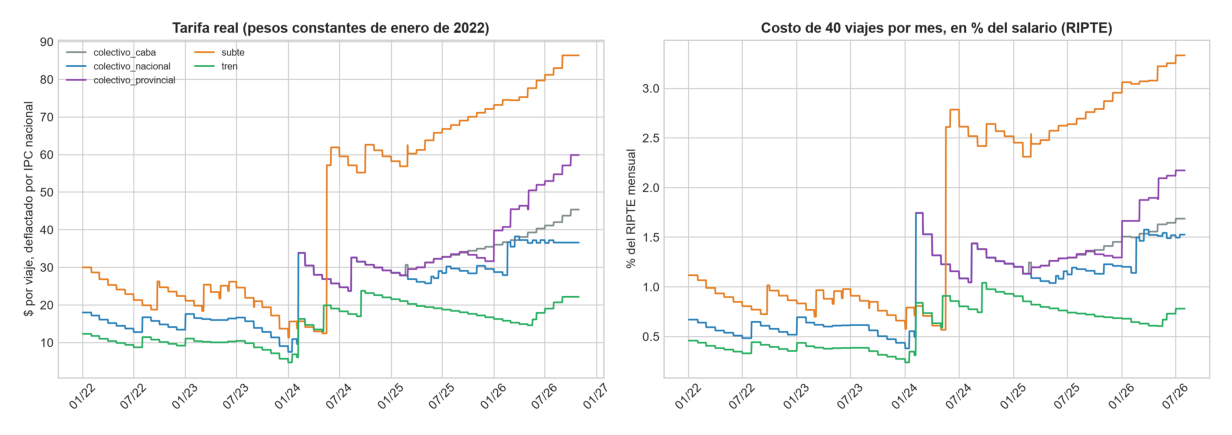

,serie,primer_valor,nominal_x,real_inicial_pesos_ene22,real_final_pesos_ene22,real_x,pct_ripte_inicial,pct_ripte_julio_2026,pct_ripte_maximo,fecha_maximo
0,colectivo_caba,2024-08-12,2.5,32.6,45.4,1.39,1.44,1.69,1.69,2026-07-01
1,colectivo_nacional,2022-01-01,41.3,18.0,36.6,2.03,0.67,1.53,1.74,2024-02-06
2,colectivo_provincial,2024-02-06,4.5,33.9,59.9,1.77,1.74,2.17,2.17,2026-07-01
3,subte,2022-01-01,58.4,30.0,86.4,2.88,1.12,3.33,3.33,2026-07-01
4,tren,2022-01-01,36.5,12.3,22.2,1.80,0.46,0.78,1.04,2024-09-16


In [8]:
figura("fig25_tarifas_reales.png", ancho=13)
tabla("tabla_tarifas_reales_resumen", cols=["serie", "primer_valor", "nominal_x", "real_inicial_pesos_ene22", "real_final_pesos_ene22", "real_x", "pct_ripte_inicial", "pct_ripte_julio_2026", "pct_ripte_maximo", "fecha_maximo"], decimales=2)

**Lectura.**

- **La inflación explica la mayor parte del aumento nominal.** El colectivo nacional pasó de $18 a $743 (×41 nominal), pero en pesos constantes de enero de 2022 pasó de $18 a $37 (×2,0). Entre 2022 y fines de 2023 la tarifa real **cayó** a $7,5 (enero de 2024) porque la tarifa nominal casi no se movió con una inflación muy alta; el salto de febrero de 2024 la llevó a $33,9, casi el doble de su valor de enero de 2022, y desde entonces la inflación la fue erosionando (unos $26 a mediados de 2024). Es decir, el salto de 2024 fue en parte una recomposición de una tarifa real que se había derrumbado, y en parte un aumento real. En el tren, de $4,7 a $16,3; en el subte, de $15,6 a $62 con el salto de mayo. El subte pasó de $30 a $86 en pesos constantes (×2,9) y el tren de $12 a $22 (×1,8).
- **El subte es el único modo cuyo peso en el salario sigue subiendo.** Cuarenta viajes mensuales en subte pasaron de 1,1% a 3,3% del RIPTE entre enero de 2022 y julio de 2026; en colectivo nacional, de 0,7% a 1,5%, y en tren, de 0,5% a 0,8%. El colectivo nacional y el tren alcanzaron su máximo relativo en 2024 y desde entonces el salario recuperó terreno; el subte, no.
- **Consecuencia para P-1.** Las variaciones de la tarifa real son más pequeñas y más graduales que las nominales, salvo en los tres saltos grandes de 2024. Por eso la elasticidad se estima con la tarifa real (y, como robustez, con la tarifa en salarios).

### 5.2 Elasticidad precio de la demanda
Se estima con tres métodos, de menos a más exigente en lo que controlan. En todos la demanda es la cantidad de usos (transacciones) del modo, semanal, de días hábiles normales (sin feriados, paros ni elecciones) cuando corresponde.

**A. Niveles semanales.** Regresión de log(demanda semanal) sobre log(tarifa) con controles de mes del año, feriados, paros y elecciones. Se muestra **con tendencia** y **sin tendencia**:

- *Sin tendencia:* el coeficiente del precio toma toda la covariación entre el nivel de la demanda y el nivel de la tarifa durante los cuatro años y medio. Si la demanda tiene su propia evolución en el tiempo (recuperación, cambios de hábitos de viaje) y la tarifa también se mueve en una dirección, el coeficiente atribuye esa evolución al precio. En este caso, el precio nominal solo sube.
- *Con tendencia:* se agrega un término lineal en el tiempo. Ahora el coeficiente del precio se identifica solo por las desviaciones de la tarifa respecto de su propia tendencia, es decir, por los saltos. Es una estimación más conservadora.

Si el resultado cambia mucho (en signo o en tamaño) entre las dos versiones, el parámetro **no está identificado**: los datos no permiten separar el efecto del precio del efecto del tiempo. Es lo que ocurre con el colectivo nacional y el tren.

**B. Diferencias interanuales (52 semanas).** Se regresa el cambio interanual de log(demanda) sobre el cambio interanual de log(tarifa). Comparar cada semana con la misma de un año antes elimina la estacionalidad y el nivel lento de cada serie; el precio queda identificado por cuánto cambió respecto del año anterior.

**C. Estudio de eventos** (con un contrafactual estacional). Para cada salto tarifario (agrupando los que están a menos de 45 días) se compara la demanda de días hábiles normales de las 6 semanas anteriores con la de las 6 semanas posteriores (dejando una semana de margen), y a ese cambio se le **resta el cambio de las mismas semanas del año anterior**. El año anterior es el contrafactual: lo que habría pasado por estacionalidad y tendencia sin el salto. La **elasticidad de arco** es el cociente entre ese cambio neto (en logaritmos) y el cambio del log de la tarifa.

In [9]:
print("A. Niveles semanales (tarifa real). Un valor por modo, con y sin tendencia:")
tabla("tabla_elasticidad_niveles", filtro="precio == 'real' and not control_salario", cols=["modo", "con_tendencia", "semanas", "elasticidad", "error_std_HAC", "ic95_inf", "ic95_sup", "R2"])
print("B. Diferencias interanuales (tarifa real):")
tabla("tabla_elasticidad_interanual", filtro="precio == 'real' and not control_salario", cols=["modo", "semanas", "elasticidad", "error_std_HAC", "ic95_inf", "ic95_sup", "R2"])

A. Niveles semanales (tarifa real). Un valor por modo, con y sin tendencia:


,modo,con_tendencia,semanas,elasticidad,error_std_HAC,ic95_inf,ic95_sup,R2
8,colectivo_nacional,False,238,-0.268,0.043,-0.351,-0.184,0.635
9,colectivo_nacional,True,238,-0.016,0.068,-0.150,0.118,0.742
10,colectivo_provincial,False,138,-0.362,0.023,-0.408,-0.317,0.785
11,colectivo_provincial,True,138,-0.256,0.053,-0.361,-0.152,0.792
12,tren,False,238,-0.180,0.028,-0.235,-0.124,0.647
13,tren,True,238,-0.037,0.034,-0.103,0.030,0.756
14,subte,False,238,-0.371,0.021,-0.412,-0.330,0.862
15,subte,True,238,-0.255,0.032,-0.317,-0.192,0.888


B. Diferencias interanuales (tarifa real):


,modo,semanas,elasticidad,error_std_HAC,ic95_inf,ic95_sup,R2
4,colectivo_nacional,186,-0.012,0.046,-0.102,0.078,0.294
5,colectivo_provincial,86,-0.268,0.058,-0.382,-0.155,0.651
6,tren,186,-0.043,0.028,-0.097,0.012,0.478
7,subte,186,-0.224,0.026,-0.275,-0.173,0.634


**Cómo leer estas tablas.** `elasticidad` es el coeficiente estimado; `error_std_HAC` es su error estándar robusto a heterocedasticidad y autocorrelación (Newey-West, 8 rezagos), necesario porque las semanas consecutivas no son independientes; `ic95_inf` y `ic95_sup` delimitan el intervalo de confianza de 95%: si **incluye el 0**, no se puede descartar que la elasticidad sea nula; `R2` es la proporción de la variación explicada por el modelo completo (con sus controles), no por el precio solo; `semanas` es el tamaño de la muestra (el colectivo provincial tiene menos porque su tarifa se conoce desde febrero de 2024).

**Lectura.**

- **Subte:** negativa y estadísticamente distinta de cero en todas las versiones: de **−0,22** (interanual) a **−0,26** (niveles con tendencia) con tarifa real. Sin tendencia da −0,37, pero esa versión no controla la evolución del tiempo y se la considera una cota superior.
- **Colectivo nacional y tren:** con tendencia o en interanual, la elasticidad es cercana a cero (de −0,04 a −0,01) y su intervalo incluye el 0. Sin tendencia sale de −0,27 y −0,18, que desaparece al agregarla: el signo y el tamaño dependen de la especificación, y por eso se concluye que **no están identificadas**.
- **Colectivo provincial:** −0,27 en interanual y −0,26 en niveles con tendencia, estadísticamente distinta de cero. Pero la muestra es corta (86 semanas y cuatro saltos moderados) y, como se verá en el apartado 5.7, el resultado desaparece al controlar por el salario real.

**Gráficos del estudio de eventos.** El primero muestra, para los modos y las ventanas alrededor de los saltos de 2024, la **razón entre las transacciones de días hábiles de 2024 y las del mismo día de 2023** (mediana móvil de 7 días hábiles). Un valor de 1,0 significa la misma demanda que un año antes; las líneas verticales marcan los saltos tarifarios. El segundo es el estudio de eventos propiamente dicho: cada punto es un salto; el eje horizontal es el aumento de la tarifa (cambio en log, neto de lo ocurrido un año antes: 0,3 equivale a +35%, 1,2 a ×3,3 y 1,4 a ×4,1) y el eje vertical es el cambio de la demanda en logaritmos, neto del año anterior (−0,2 equivale a −18%). Si el precio redujera la demanda, los puntos deberían bajar hacia la derecha.

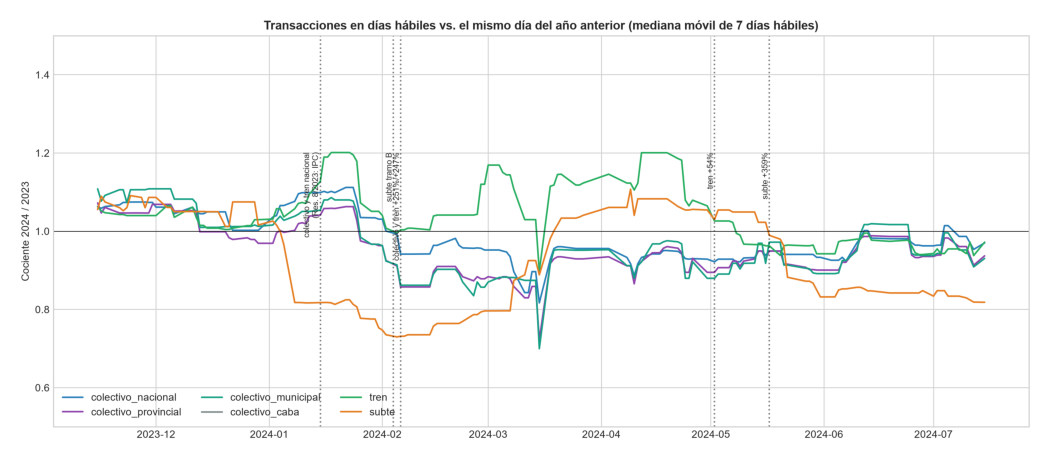

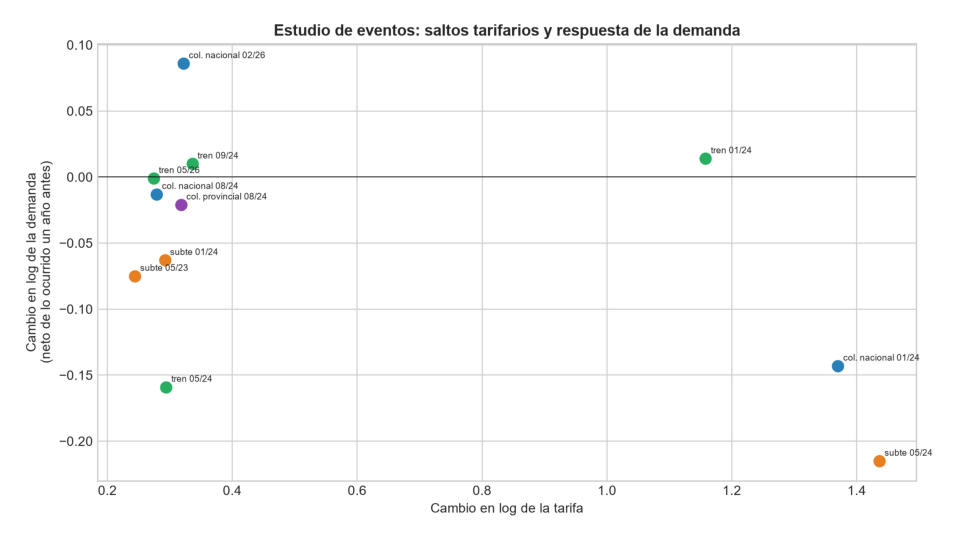

Estudio de eventos (tarifa real):


,modo,desde,hasta,tarifa_x,dlog_tarifa,dlog_demanda_neto,cambio_demanda_pct,elasticidad_arco,dlog_tarifa_real,elasticidad_arco_real
0,colectivo_nacional,2024-01-15,2024-02-06,3.93,1.370,-0.143,-13.3,-0.104,1.207,-0.118
1,colectivo_nacional,2024-08-12,2024-08-12,1.32,0.279,-0.013,-1.3,-0.045,0.420,-0.030
2,colectivo_nacional,2026-02-18,2026-02-18,1.38,0.322,0.086,9.0,0.268,0.323,0.268
3,colectivo_provincial,2024-08-12,2024-08-12,1.37,0.318,-0.021,-2.1,-0.066,0.255,-0.082
4,colectivo_provincial,2025-03-01,2025-03-01,1.12,0.115,0.162,17.6,1.410,0.201,0.806
5,colectivo_provincial,2026-03-01,2026-03-01,1.08,0.073,-0.046,-4.5,-0.635,0.075,-0.618
6,colectivo_provincial,2026-05-04,2026-05-04,1.06,0.054,0.036,3.7,0.667,0.046,0.780
7,subte,2023-05-06,2023-06-05,1.28,0.244,-0.075,-7.2,-0.306,0.212,-0.353
8,subte,2024-01-05,2024-02-04,1.34,0.292,-0.063,-6.1,-0.215,0.039,-1.613
9,subte,2024-05-17,2024-06-01,4.21,1.436,-0.215,-19.4,-0.150,1.484,-0.145


Banda placebo (fechas sin cambio de precio):


,modo,n_placebos,p05_dlog_demanda,p95_dlog_demanda,sd_dlog_demanda
0,colectivo_nacional,20,-0.043,0.026,0.023
1,tren,35,-0.052,0.050,0.034
2,subte,22,-0.007,0.083,0.033


In [10]:
figura("fig13_usos_yoy_tarifas_2024.png")
figura("fig14_estudio_eventos.png", ancho=10)
print("Estudio de eventos (tarifa real):")
tabla("tabla_estudio_eventos", cols=["modo", "desde", "hasta", "tarifa_x", "dlog_tarifa", "dlog_demanda_neto", "cambio_demanda_pct", "elasticidad_arco", "dlog_tarifa_real", "elasticidad_arco_real"])
print("Banda placebo (fechas sin cambio de precio):")
tabla("tabla_placebo_eventos")

**Qué muestran los gráficos.**

- **Primer gráfico.** El **subte** cae a 0,73–0,82 de la demanda del año anterior entre enero y marzo de 2024, antes del salto grande de mayo. Esa caída coincide con el **cierre de la línea D** (8 de enero a 6 de marzo de 2024) y con los saltos de enero y febrero, y por eso el análisis del subte se hace **sin la línea D**. Cuando la línea reabre, la razón vuelve a 1,05–1,10 hacia abril. Después del salto de **+359%** del 17 de mayo, la razón del subte baja de alrededor de 1,05 a 0,85 y se mantiene en ese nivel hasta julio: es la caída persistente más clara del gráfico. En el **colectivo y el tren**, la razón baja de 1,10–1,20 a 0,9–1,0 alrededor del 6 de febrero; la caída es menor y se recupera en parte en marzo y abril.
- **Segundo gráfico.** Los dos saltos grandes cuya demanda cae son el del **colectivo nacional de enero–febrero de 2024** (−0,14 en logaritmos, −13%) y el del **subte de mayo de 2024** (−0,22, −19%). El **tren**, ante un salto de tarifa también grande (×3,2), **no cae** (+0,01): ese contraste entre modos es lo que impide atribuir sin más la caída a la tarifa. Entre los saltos moderados (puntos a la izquierda), el subte baja entre 6% y 10% (los tres moderados), el tren de mayo de 2024 baja 15% y los demás están cerca de cero. El tren de mayo de 2024 queda a una semana del **paro general del 9 de mayo**, un efecto superpuesto que el método no separa. El colectivo nacional de febrero de 2026 **sube** 9%, lo contrario del signo esperado, lo que indica que ahí actuó otro factor.

**Banda placebo.** Para saber si un cambio de demanda es grande o normal, se repite el mismo cálculo del estudio de eventos en fechas donde **la tarifa no cambió** (placebos: 20 para el colectivo nacional, 35 para el tren, 22 para el subte). La tabla da, para cada modo, los percentiles 5 y 95 del cambio neto de la demanda en log que se observa **sin** cambio de precio, y su desvío. Es la medida del ruido: un salto solo se considera distinguible del azar si su cambio de demanda cae **fuera** de esa banda. Para el colectivo nacional la banda es de −0,043 a +0,026; para el tren, de −0,052 a +0,050; para el subte, de −0,007 a +0,083.

Con esa vara:

- **Colectivo nacional:** enero–febrero de 2024 (−0,143) cae por debajo de la banda; agosto de 2024 (−0,013) queda dentro (no se distingue del ruido); febrero de 2026 (+0,086) queda por encima, con signo contrario al esperado.
- **Subte:** los cuatro saltos (−0,075, −0,063, −0,215 y −0,110) caen por debajo de −0,007, es decir, **fuera de la banda** y todos con el signo esperado. Es la evidencia más consistente del apartado.
- **Tren:** solo el de mayo de 2024 (−0,159) cae fuera de la banda, y coincide con el paro general; los otros tres están dentro.

### 5.3 Control sintético para los saltos tarifarios del colectivo nacional
El estudio de eventos usa el año anterior como contrafactual, pero un salto tarifario grande puede coincidir con otros cambios (precios en general, ingreso, vacaciones). El **control sintético** construye un AMBA "sin salto" como combinación ponderada de **ciudades del interior** del país (también con SUBE, y cuyas tarifas no cambiaron con el aumento nacional del AMBA), de modo que esa combinación replique la demanda del AMBA en las 52 semanas previas al salto. La diferencia entre el AMBA real y el AMBA sintético después del salto es el efecto estimado. Los controles absorben los shocks nacionales comunes (inflación, ingreso, clima); no absorben lo que sea propio del AMBA.

En los gráficos, la línea azul es el AMBA real y la línea punteada el AMBA sintético, ambos en log de usos relativo al promedio previo; la línea vertical marca el salto. Si el salto hubiera reducido la demanda, la línea azul debería quedar por debajo de la punteada después de la línea vertical.

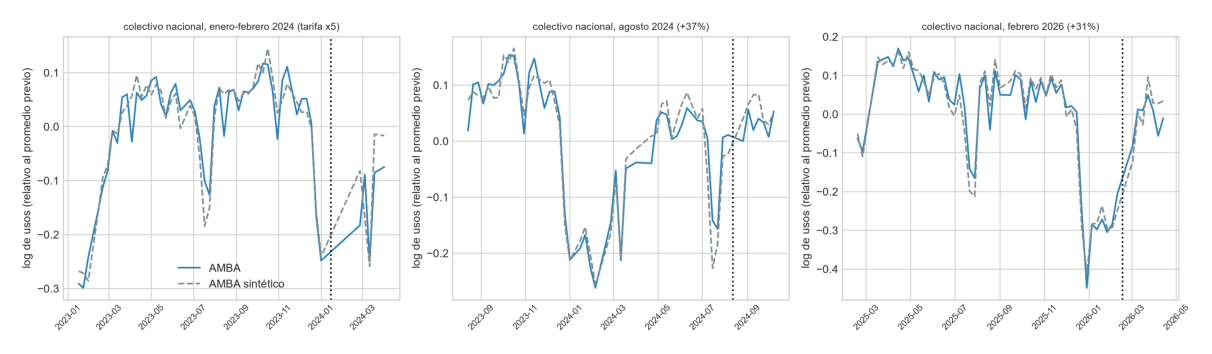

,evento,brecha_log,cambio_pct,rmspe_previo,rmspe_posterior,razon_post_pre,p_placebos,n_placebos,placebo_p5_brecha,placebo_p95_brecha
0,"colectivo nacional, enero-febrero 2024 (tarifa...",-0.028,-2.8,0.030,0.071,2.38,0.433,30,-0.203,0.228
1,"colectivo nacional, agosto 2024 (+37%)",-0.026,-2.5,0.029,0.034,1.15,0.267,30,-0.087,0.127
2,"colectivo nacional, febrero 2026 (+31%)",-0.015,-1.5,0.028,0.046,1.63,0.267,30,-0.176,0.134


,evento,donante,peso
0,"colectivo nacional, enero-febrero 2024 (tarifa...",SANTA FE - SN,0.233
1,"colectivo nacional, enero-febrero 2024 (tarifa...",JUJUY - SN,0.215
2,"colectivo nacional, enero-febrero 2024 (tarifa...",BUENOS AIRES - GENERAL PUEYRREDON,0.209
3,"colectivo nacional, enero-febrero 2024 (tarifa...",RÍO NEGRO - SAN CARLOS DE BARILOCHE,0.131
4,"colectivo nacional, enero-febrero 2024 (tarifa...",SANTA FE - SANTA FE,0.068
5,"colectivo nacional, enero-febrero 2024 (tarifa...",NEUQUÉN - NEUQUEN,0.061


In [11]:
figura("fig18_control_sintetico.png", ancho=13)
tabla("tabla_control_sintetico", cols=["evento", "brecha_log", "cambio_pct", "rmspe_previo", "rmspe_posterior", "razon_post_pre", "p_placebos", "n_placebos", "placebo_p5_brecha", "placebo_p95_brecha"])
tabla("tabla_control_sintetico_donantes", filtro="evento.str.contains('enero-febrero')")

**Cómo leer la tabla.** `brecha_log` y `cambio_pct` son la diferencia (AMBA real menos sintético) promedio posterior al salto, en logaritmos y en porcentaje. `rmspe_previo` es el error cuadrático medio de ajuste de la combinación en las 52 semanas anteriores (qué tan bien imita al AMBA antes del salto: 0,03 significa un error de alrededor de 3%) y `rmspe_posterior` el mismo error después; `razon_post_pre` es su cociente: si el efecto del salto es real, el error posterior debería ser mucho mayor que el previo. Para saber **cuán grande es una razón** se hace una **inferencia por placebos en el espacio**: se aplica el mismo procedimiento a cada una de las ciudades donantes como si hubiera sido la tratada, y `p_placebos` es la proporción de esas ciudades que tienen una razón igual o mayor a la del AMBA (con `n_placebos` ciudades). `placebo_p5_brecha` y `placebo_p95_brecha` son los percentiles 5 y 95 de la brecha de esos placebos. La última tabla muestra las ciudades que más pesan en el control del primer salto (`peso` suma 1).

**Lectura.** El control sintético da −2,8%, −2,5% y −1,5% para los tres saltos tarifarios del colectivo nacional (enero–febrero de 2024, agosto de 2024 y febrero de 2026), con `p_placebos` de 0,43, 0,27 y 0,27: entre 27% y 43% de las ciudades sin tratamiento muestran una brecha igual o mayor por puro azar, de modo que **ningún efecto es distinguible del ruido**. **No confirma** el −13% del estudio de eventos para enero–febrero de 2024 (es una discrepancia entre dos métodos, no una confirmación mutua). Las limitaciones son reales: los precios de las ciudades donantes no se pudieron verificar y varias son turísticas, con estacionalidad distinta; en el primer gráfico, además, los tramos rectos corresponden a semanas sin datos suficientes de días normales. Conclusión: el colectivo cae poco ante el precio, y el −13% queda como cota superior poco confiable.

### 5.4 Sustitución entre modos y Granger
Pregunta: si sube la tarifa de un modo, ¿se desplaza demanda a los otros? Si fuera así, el **coeficiente cruzado** (efecto de la tarifa de un modo sobre la demanda de otro) sería **positivo**: más caro el modo A, más demanda en el modo B. Se estima de dos maneras.

**A. Efecto cruzado en diferencias interanuales.** Para cada modo, se regresa el cambio interanual (52 semanas) de log(demanda) sobre el cambio interanual de log(tarifa real) de **los tres modos a la vez** (la propia y las de los otros dos), con controles de feriados, paros y elecciones. Cada fila de la tabla es un coeficiente:

- `demanda_de`: modo cuya demanda se explica; `tarifa_de`: tarifa que se usa como regresora; `tipo`: **propia** (la tarifa del mismo modo, o sea, la elasticidad propia) o **cruzada** (la de otro modo).
- `coeficiente`: elasticidad estimada; `error_std_HAC`, `ic95_inf` e `ic95_sup`: como en el apartado 5.2.
- `VIF` (factor de inflación de la varianza): mide cuánto se confunde cada tarifa con las demás. Un VIF de 1 indica que no hay colinealidad; valores de 5 o más indican que los coeficientes no se pueden separar con confiabilidad. Acá las tarifas de los tres modos subieron al mismo tiempo en 2024, y por eso los VIF llegan a 4–7.

**B. Granger.** La prueba de Granger pregunta si agregar los valores pasados de la tarifa a una regresión de la demanda sobre sus propios valores pasados **mejora significativamente** la predicción. Las series se llevan primero a estacionariedad (primera diferencia del logaritmo de la demanda, descontados feriados, paros, elecciones y mes; primera diferencia del logaritmo de la tarifa real) y se verifica con ADF y KPSS. El número de rezagos se elige por criterio AIC (hasta 8 semanas). `rezago_AIC` es el elegido, `p_valor` el de la prueba F de que los rezagos del precio no aportan, y `p_Holm` el p-valor corregido por las **nueve** pruebas de cada sentido (corrección de Holm, que controla la probabilidad de algún falso positivo entre varias pruebas). Como control, se prueba también el sentido inverso (demanda → tarifa).

In [12]:
print("A. Efecto cruzado, diferencias interanuales (tarifa real):")
tabla("tabla_efecto_cruzado_interanual", cols=["demanda_de", "tarifa_de", "tipo", "coeficiente", "error_std_HAC", "ic95_inf", "ic95_sup", "VIF", "semanas"])
print("B. Granger (tarifa -> demanda):")
tabla("tabla_granger_precio_demanda", filtro="sentido == 'tarifa -> demanda'", cols=["demanda_de", "tarifa_de", "tipo", "rezago_AIC", "p_valor", "p_Holm"])
print("Estacionariedad de las series usadas en Granger:")
tabla("tabla_estacionariedad_granger")

A. Efecto cruzado, diferencias interanuales (tarifa real):


,demanda_de,tarifa_de,tipo,coeficiente,error_std_HAC,ic95_inf,ic95_sup,VIF,semanas
0,colectivo_nacional,colectivo_nacional,propia,-0.114,0.078,-0.267,0.038,4.4,186
1,colectivo_nacional,tren,cruzada,0.164,0.082,0.003,0.325,6.9,186
2,colectivo_nacional,subte,cruzada,-0.104,0.044,-0.189,-0.018,2.4,186
3,tren,colectivo_nacional,cruzada,-0.210,0.028,-0.266,-0.155,4.4,186
4,tren,tren,propia,0.216,0.034,0.149,0.282,6.9,186
5,tren,subte,cruzada,-0.131,0.030,-0.190,-0.072,2.4,186
6,subte,colectivo_nacional,cruzada,0.022,0.061,-0.097,0.142,4.4,186
7,subte,tren,cruzada,0.056,0.063,-0.068,0.180,6.9,186
8,subte,subte,propia,-0.262,0.031,-0.323,-0.201,2.4,186


B. Granger (tarifa -> demanda):


,demanda_de,tarifa_de,tipo,rezago_AIC,p_valor,p_Holm
0,colectivo_nacional,colectivo_nacional,propia,3,0.797,1.000
1,colectivo_nacional,tren,cruzada,3,0.793,1.000
2,colectivo_nacional,subte,cruzada,3,0.311,1.000
3,tren,colectivo_nacional,cruzada,5,0.026,0.181
4,tren,tren,propia,5,0.018,0.141
5,tren,subte,cruzada,4,0.181,1.000
6,subte,colectivo_nacional,cruzada,3,0.993,1.000
7,subte,tren,cruzada,3,0.397,1.000
8,subte,subte,propia,4,0.002,0.019


Estacionariedad de las series usadas en Granger:


,serie,modo,p_ADF,p_KPSS,decision
0,"demanda (dif. log, ajustada)",colectivo_nacional,0.000,0.100,estacionaria
1,"demanda (dif. log, ajustada)",tren,0.000,0.061,estacionaria
2,"demanda (dif. log, ajustada)",subte,0.000,0.100,estacionaria
3,tarifa real (dif. log),colectivo_nacional,0.000,0.100,estacionaria
4,tarifa real (dif. log),tren,0.005,0.100,estacionaria
5,tarifa real (dif. log),subte,0.000,0.100,estacionaria


**Lectura.**

- **Efecto cruzado interanual.** Las elasticidades propias son −0,26 en el subte (distinta de cero), −0,11 en el colectivo nacional (el intervalo incluye 0) y **+0,22 en el tren, con signo positivo**, lo que no tiene una interpretación económica razonable y es síntoma de colinealidad. Aparecen coeficientes cruzados distintos de cero (por ejemplo, la demanda del tren frente a la tarifa del colectivo, −0,21), pero con VIF de 4 a 7 y con signos que, en varios casos, serían de complementariedad (el modo B cae cuando sube el A), no de sustitución. Como las tres tarifas se movieron juntas, **los coeficientes cruzados no se pueden separar** y no se interpretan como efectos. No hay ningún coeficiente cruzado positivo y estable que sugiera sustitución.
- **Granger.** Solo hay un par significativo luego de la corrección de Holm: la **tarifa propia del subte** frente a la **demanda del subte** (`rezago_AIC` = 4 semanas, `p_valor` = 0,002, `p_Holm` = 0,019). Se lee así: *conocer los cambios de la tarifa del subte de las últimas 4 semanas mejora la predicción del cambio de la demanda del subte de esta semana, más allá de lo que ya explica su propio pasado*. Es compatible con una respuesta de la demanda al precio con un retardo de alrededor de un mes. **No prueba causalidad**: un resultado de Granger indica precedencia predictiva y podría reflejar cualquier otro cambio que acompañe a los aumentos de tarifa (por ejemplo, anuncios o paquetes de medidas). Los pares tren–tren y tren–colectivo tienen `p_valor` de 0,018 y 0,026 pero no superan la corrección de Holm (0,14 y 0,18). En el sentido inverso (demanda → tarifa) no hay ningún par significativo tras la corrección: la tarifa no parece fijarse en respuesta a la demanda.
- **Sustitución.** En conjunto, no hay evidencia de que un aumento de la tarifa de un modo traslade demanda a otro. El apartado 5.6 muestra la misma ausencia de sustitución en los días de paro.

### 5.5 ¿Reaccionan menos las líneas de zonas de mayor ingreso? (contraste de ingreso)
Hipótesis fijada **antes** de correr el análisis: las líneas que atraviesan zonas de mayor ingreso (en particular la línea D) reaccionan menos a los saltos tarifarios del subte, porque sus usuarios son menos sensibles al precio.

**Datos externos.** El ingreso por línea no está en SUBE. Se construyó con la **Encuesta Anual de Hogares (EAH) de la Ciudad de Buenos Aires** (Dirección General de Estadística y Censos, IDECBA), que da el ingreso per cápita familiar medio por comuna. Cada estación del subte se ubicó en su comuna con los datos geográficos de **BA Data** (comunas y estaciones de subte), y cada línea recibió el **promedio del índice de ingreso de sus estaciones** (ingreso de la comuna relativo al total de la Ciudad, promedio 2022–2025; 1,0 es el promedio de la Ciudad). La EAH cubre solo la Ciudad: el índice describe la zona de las estaciones, no necesariamente el ingreso de quienes viajan.

**Método.** Panel línea × semana con **efecto fijo por semana**, que absorbe todo lo que afecta a todas las líneas por igual (el precio mismo, la inflación, los feriados) y deja solo la diferencia entre líneas. El coeficiente de interés, `delta`, es la **interacción entre el índice de ingreso de la línea y el log de la tarifa real**: mide cuánto cambia la elasticidad de una línea por cada unidad de su índice de ingreso. La hipótesis predice `delta` **positivo** (a más ingreso, elasticidad menos negativa). La línea D estuvo cerrada del 8 de enero al 6 de marzo de 2024, lo que confunde el salto de ese período; por eso se prueba con dos definiciones de exclusión (`cierre` y `cierre ampliado`). Cada una se estima con un índice continuo y con un contraste simple (D contra el resto) y con o sin tendencia propia por línea. `p_permutacion` es la fracción de reasignaciones de los índices entre líneas que dan un `delta` tan extremo como el observado (720 con el índice continuo; solo 5 distintas con el contraste simple).

,linea,estaciones,comunas,indice_comuna_2022_2025
0,D,16,"1, 2, 3, 13, 14",1.235
1,B,17,"1, 3, 5, 12, 15",0.961
2,A,18,"1, 3, 5, 6, 7",0.940
3,H,12,"2, 3, 4",0.930
4,C,9,1,0.898
5,E,18,"1, 3, 5, 6, 7",0.885


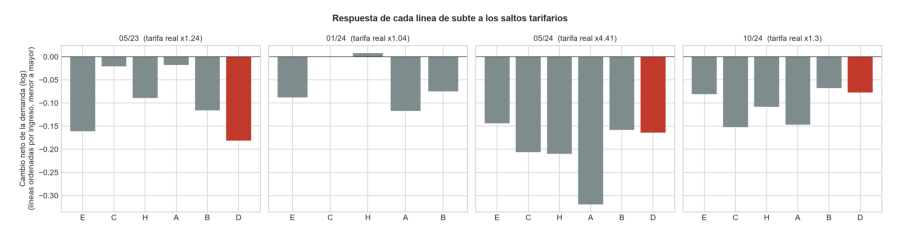

,definicion_D_excluida,especificacion,tendencia_por_linea,observaciones,delta,error_std,p_permutacion
0,cierre,indice continuo,False,1419,-0.490,0.044,0.015
1,cierre,indice continuo,True,1419,-0.052,0.064,0.539
2,cierre,"D contra A,B,C,E",False,1181,-0.123,0.013,0.200
3,cierre,"D contra A,B,C,E",True,1181,-0.005,0.019,0.800
4,cierre ampliado,indice continuo,False,1411,-0.580,0.036,0.015
5,cierre ampliado,indice continuo,True,1411,-0.225,0.068,0.026
6,cierre ampliado,"D contra A,B,C,E",False,1173,-0.149,0.011,0.200
7,cierre ampliado,"D contra A,B,C,E",True,1173,-0.055,0.023,0.200


In [13]:
tabla("tabla_lineas_subte_ingreso", cols=["linea", "estaciones", "comunas", "indice_comuna_2022_2025"])
figura("fig15_eventos_subte_por_linea.png", ancho=10)
tabla("tabla_panel_subte_delta", cols=["definicion_D_excluida", "especificacion", "tendencia_por_linea", "observaciones", "delta", "error_std", "p_permutacion"])

**Lectura.** El índice de ingreso ordena a las líneas así: D (1,24), B (0,96), A (0,94), H (0,93), C (0,90) y E (0,89); la D es la única claramente por encima del promedio. El coeficiente `delta` es **negativo en las ocho especificaciones**, y la hipótesis predecía el signo contrario. En tres la permutación lo marca como significativo (p = 0,015 en dos especificaciones con índice continuo y sin tendencia propia por línea, y p = 0,026 con cierre ampliado y tendencia), pero con el **signo opuesto al esperado** (las líneas de más ingreso reaccionan *más*, no menos); y con la especificación base con tendencia propia por línea, `delta` es −0,05 con p = 0,54. El resultado cambia con la especificación, así que no es robusto. Además, con solo seis líneas, el p mínimo posible del contraste D contra el resto es 0,20: esa prueba **no tiene poder** para distinguir un efecto. Se reporta como **sin respaldo** (la hipótesis no se confirma) y con **poder bajo** (no se la puede refutar con estos datos).

### 5.6 Hitos de calendario: feriados, paros, elecciones y pandemia
Para cada día especial se calcula el **cociente** entre su demanda (transacciones) y la **mediana del mismo día de la semana en las ±4 semanas vecinas** (sin contar feriados, paros ni elecciones). Un cociente de 0,5 significa la mitad de lo habitual para ese día. La **banda de días ordinarios** (cociente entre 0,78 y 1,13 para el colectivo; 0,78–1,11 para el tren; 0,83–1,14 para el subte) mide la variación normal: son los percentiles 2,5 y 97,5 del mismo cociente en días laborables sin ningún hito. Un hito solo se considera un efecto cuando queda **fuera de la banda**.

**Clasificación de los paros.** Un "paro" no es un único tipo de evento: la demanda de cada modo depende de **quién paró**. Se distinguen cuatro tipos: paros del **colectivo** (UTA, tres casos), del **tren** (La Fraternidad, un caso), de **tren y subte** conjuntamente (un caso) y **generales de la CGT** (cuatro casos; en el del 10 de abril de 2025 pararon el subte y los trenes, pero no el colectivo, porque la UTA no adhirió). Las **elecciones** se separan según hubo **gratuidad** del transporte (agosto, octubre y noviembre de 2023; el balotaje no tiene fuente y se infiere del dato) o no se observó (las tres elecciones de 2025).

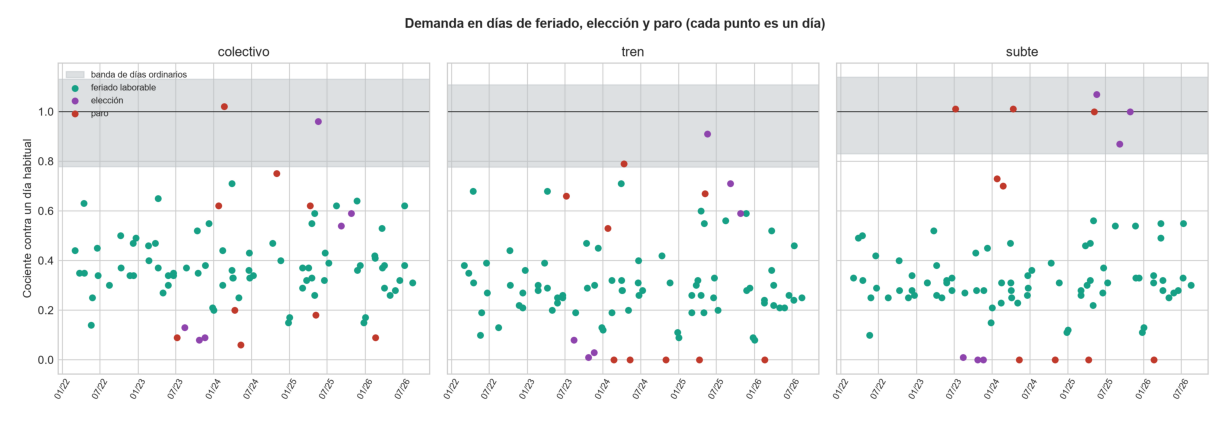

Resumen por tipo de hito (todos los paros juntos):


,tipo,modo,dias,mediana_cociente,minimo,maximo,banda_ruido_inf,banda_ruido_sup,pct_fuera_de_banda
0,eleccion,colectivo,6,0.34,0.08,0.96,0.78,1.13,83
1,eleccion,tren,6,0.34,0.01,0.91,0.78,1.11,83
2,eleccion,subte,6,0.44,0.00,1.07,0.83,1.14,50
3,feriado,colectivo,76,0.36,0.14,0.71,0.78,1.13,100
4,feriado,tren,76,0.28,0.08,0.71,0.78,1.11,100
5,feriado,subte,76,0.31,0.10,0.56,0.83,1.14,100
6,feriado en fin de semana,colectivo,18,0.88,0.39,1.11,0.78,1.13,28
7,feriado en fin de semana,tren,18,0.84,0.43,1.14,0.78,1.11,33
8,feriado en fin de semana,subte,18,0.96,0.45,1.90,0.83,1.14,33
9,paro,colectivo,9,0.20,0.06,1.02,0.78,1.13,89


In [14]:
figura("fig17_hitos_cociente.png", ancho=13)
print("Resumen por tipo de hito (todos los paros juntos):")
tabla("tabla_hitos_resumen", cols=["tipo", "modo", "dias", "mediana_cociente", "minimo", "maximo", "banda_ruido_inf", "banda_ruido_sup", "pct_fuera_de_banda"])

Paros y elecciones por tipo (mediana de cociente por modo):


,tipo,subtipo,modo,dias,mediana_cociente,minimo,maximo,banda_ruido_inf,banda_ruido_sup
0,eleccion,con gratuidad,colectivo,2,0.11,0.08,0.13,0.78,1.13
1,eleccion,con gratuidad,tren,2,0.04,0.01,0.08,0.78,1.11
2,eleccion,con gratuidad,subte,2,0.00,0.00,0.01,0.83,1.14
3,eleccion,con gratuidad (inferida del dato),colectivo,1,0.09,0.09,0.09,0.78,1.13
4,eleccion,con gratuidad (inferida del dato),tren,1,0.03,0.03,0.03,0.78,1.11
5,eleccion,con gratuidad (inferida del dato),subte,1,0.00,0.00,0.00,0.83,1.14
6,eleccion,sin gratuidad aparente,colectivo,3,0.59,0.54,0.96,0.78,1.13
7,eleccion,sin gratuidad aparente,tren,3,0.71,0.59,0.91,0.78,1.11
8,eleccion,sin gratuidad aparente,subte,3,1.00,0.87,1.07,0.83,1.14
9,paro,colectivo (UTA),colectivo,3,0.18,0.09,0.20,0.78,1.13


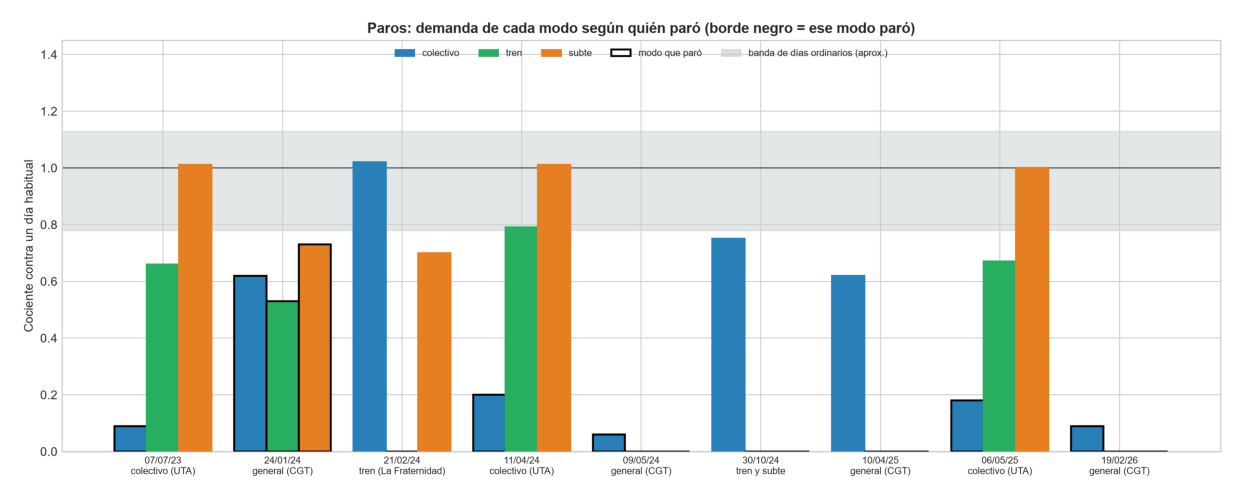

Cada paro: cociente del modo que paró y de los que no pararon:


,fecha,paro,modo,rol,cociente,posicion
0,2023-07-07,colectivo (UTA),colectivo,paró,0.09,bajo la banda
1,2023-07-07,colectivo (UTA),tren,no paró,0.66,bajo la banda
2,2023-07-07,colectivo (UTA),subte,no paró,1.01,dentro de la banda
3,2024-01-24,general (CGT),colectivo,paró,0.62,bajo la banda
4,2024-01-24,general (CGT),tren,paró,0.53,bajo la banda
5,2024-01-24,general (CGT),subte,paró,0.73,bajo la banda
6,2024-02-21,tren (La Fraternidad),colectivo,no paró,1.02,dentro de la banda
7,2024-02-21,tren (La Fraternidad),tren,paró,0.00,bajo la banda
8,2024-02-21,tren (La Fraternidad),subte,no paró,0.70,bajo la banda
9,2024-04-11,colectivo (UTA),colectivo,paró,0.20,bajo la banda


In [15]:
print("Paros y elecciones por tipo (mediana de cociente por modo):")
tabla("tabla_hitos_resumen_subtipo", cols=["tipo", "subtipo", "modo", "dias", "mediana_cociente", "minimo", "maximo", "banda_ruido_inf", "banda_ruido_sup"])
figura("fig26_paros_por_tipo.png", ancho=13)
print("Cada paro: cociente del modo que paró y de los que no pararon:")
tabla("tabla_paros_modo_propio_vs_otros", cols=["fecha", "paro", "modo", "rol", "cociente", "posicion"])

**Cómo leer las tablas.** `mediana_cociente`, `minimo` y `maximo` resumen el cociente de los días del grupo; `banda_ruido_inf` y `banda_ruido_sup` son los límites de la banda de días ordinarios de ese modo; `pct_fuera_de_banda` es el porcentaje de días del grupo con cociente fuera de la banda. En la última tabla, `rol` indica si ese modo paró o no ese día y `posicion` si su cociente quedó por debajo, dentro o por encima de la banda.

**Lectura.**

- **Feriados.** Los feriados laborables tienen una mediana de 0,36 (colectivo), 0,28 (tren) y 0,31 (subte), con el 100% de los días fuera de la banda. Los feriados que caen en fin de semana casi no se distinguen de un fin de semana común (mediana de 0,84 a 0,96).
- **Elecciones.** El efecto depende de la **gratuidad**, no de la elección en sí. Con gratuidad, la demanda cae a una fracción mínima (entre 0,08 y 0,13 en el colectivo, entre 0,01 y 0,08 en el tren y entre 0,00 y 0,01 en el subte; las fuentes no confirman que el subte de la Ciudad haya adherido a la gratuidad, pero el dato muestra cero igual). Sin gratuidad aparente (2025), la mediana del colectivo es 0,59 de un día normal, la del tren 0,71 y la del subte 1,00: hay una baja de colectivo y tren, pero sin el colapso de las elecciones gratuitas. La mediana de 0,34 del colectivo que mezcla todas las elecciones no describe ninguno de los dos grupos.
- **Paros: el modo que para cae a casi cero.** Cuando paró el propio modo, el cociente mediano es de 0,14 en el colectivo y de 0,00 en el tren y el subte. La excepción es el **paro general del 24 de enero de 2024** (0,53 a 0,73), con adhesión parcial; ese día cae en un mes con datos reconstruidos desde transacciones.
- **Paros: lo que les pasa a los modos que no pararon.** El supuesto de partida es razonable: si para el colectivo, parte de sus pasajeros podría pasar al subte y su demanda subiría. **No se observa.** En los tres paros del colectivo (UTA) el subte queda en 1,00 a 1,01, **dentro de la banda** (0,83–1,14): no hay aumento detectable. En cambio, el **tren cae a 0,66–0,79** (fuera de la banda en dos de los tres), aunque no paró. Una explicación posible, que este trabajo no pone a prueba, es la **complementariedad**: muchos usuarios del tren llegan a las estaciones en colectivo, de modo que sin colectivo no completan el viaje; los del subte, con una red de acceso más peatonal y que cubre otra zona, serían menos dependientes del colectivo.
- **Cuando paran el tren y el subte, el colectivo no absorbe esa demanda.** El 30 de octubre de 2024 (paro de tren y subte, sin adhesión de la UTA) el colectivo cae a 0,75, y el 10 de abril de 2025 (paro general sin adhesión de la UTA) a 0,62. No hay sustitución hacia el colectivo; la demanda total se reduce. En el paro de trenes de febrero de 2024, el colectivo se mantiene (1,02) y el subte cae a 0,70, fuera de la banda; con un solo evento no se puede distinguir la causa.
- **Cautelas.** Son nueve paros, con adhesión distinta en cada uno; el cociente no distingue entre quienes no viajan y quienes viajaron por otro medio ni controla el clima ni el aviso previo del paro. La tarjeta SUBE registra usos, no la intención de viajar.

**Pandemia (solo descriptivo).** Demanda semanal de días hábiles de cada modo como porcentaje del promedio de enero–marzo de 2020.

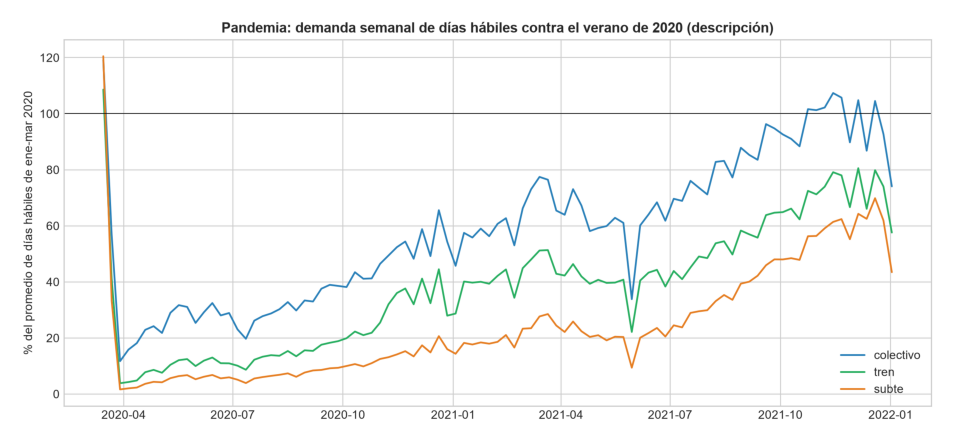

,modo,base_enero_marzo_2020_dia_habil,semana_minima,cociente_minimo,cociente_dic_2020,cociente_dic_2021
0,colectivo,8446362,2020-03-29,0.117,0.570,0.972
1,tren,1318868,2020-03-29,0.038,0.365,0.751
2,subte,905989,2020-03-29,0.016,0.172,0.646


In [16]:
figura("fig16_covid_descriptivo.png", ancho=10)
tabla("tabla_covid_descriptivo")

**Lectura de la pandemia.** El mínimo semanal fue de 12% (colectivo), 4% (tren) y 2% (subte) del nivel de enero–marzo de 2020; a fines de 2021 los modos habían vuelto a 97%, 75% y 65%. Es descriptivo: no se compara contra un nivel previo "normal" porque solo se dispone del período del 6 de enero al 8 de marzo de 2020 (temporada baja) y de ninguna base anual completa.

### 5.7 Robustez: ingreso real y síntesis de P-1

**¿Qué pasa con la elasticidad al controlar por el salario real?** En el apartado 5.2 el precio se mide en términos reales (deflactado por el IPC), pero el poder de compra de los salarios también se movió en el período y podría estar asociado tanto al precio como a la demanda. Se repiten los métodos A y B con dos variantes: (i) agregando como regresora el **salario real** (RIPTE deflactado por IPC) y (ii) midiendo la tarifa **en salarios** (tarifa / RIPTE), que mide cuánto representa el viaje del salario. El RIPTE es un salario formal, nacional y mensual: aproxima el ingreso de los trabajadores registrados, no el de todos los usuarios. En los meses sin dato se repite el último salario real.

In [17]:
ia = pd.read_csv(TAB / "tabla_elasticidad_interanual.csv").query("precio == 'real' and not control_salario").set_index("modo")["elasticidad"]
nv = pd.read_csv(TAB / "tabla_elasticidad_niveles.csv").query("precio == 'real' and not control_salario and con_tendencia").set_index("modo")["elasticidad"]
cs = pd.read_csv(TAB / "tabla_elasticidad_control_salario.csv")
def col(metodo, precio, ctrl, tend=None):
    d = cs[(cs.metodo == metodo) & (cs.precio == precio) & (cs.control_salario == ctrl)]
    if tend is not None:
        d = d[d.con_tendencia == tend]
    return d.set_index("modo")["elasticidad"]
tab = pd.DataFrame({
    "interanual: tarifa real": ia,
    "interanual: + salario real": col("interanual", "real", True),
    "interanual: tarifa en salarios": col("interanual", "en salarios (RIPTE)", False),
    "niveles c/tend.: tarifa real": nv,
    "niveles c/tend.: + salario real": col("niveles", "real", True, True),
    "niveles c/tend.: tarifa en salarios": col("niveles", "en salarios (RIPTE)", False, True)})
display(tab.round(3))
print("Intervalos de confianza de 95% (interanual):")
tabla("tabla_elasticidad_control_salario", filtro="metodo == 'interanual'", cols=["precio", "control_salario", "modo", "semanas", "elasticidad", "ic95_inf", "ic95_sup"])

,interanual: tarifa real,interanual: + salario real,interanual: tarifa en salarios,niveles c/tend.: tarifa real,niveles c/tend.: + salario real,niveles c/tend.: tarifa en salarios
modo,,,,,,
colectivo_nacional,-0.012,-0.018,0.030,-0.016,-0.022,0.051
colectivo_provincial,-0.268,-0.063,-0.206,-0.256,-0.102,-0.202
tren,-0.043,-0.032,-0.021,-0.037,-0.030,-0.004
subte,-0.224,-0.145,-0.214,-0.255,-0.164,-0.249


Intervalos de confianza de 95% (interanual):


,precio,control_salario,modo,semanas,elasticidad,ic95_inf,ic95_sup
8,real,True,colectivo_nacional,186,-0.018,-0.100,0.064
9,real,True,colectivo_provincial,86,-0.063,-0.155,0.028
10,real,True,tren,186,-0.032,-0.073,0.009
11,real,True,subte,186,-0.145,-0.193,-0.097
20,en salarios (RIPTE),False,colectivo_nacional,186,0.030,-0.054,0.114
21,en salarios (RIPTE),False,colectivo_provincial,86,-0.206,-0.288,-0.123
22,en salarios (RIPTE),False,tren,186,-0.021,-0.083,0.041
23,en salarios (RIPTE),False,subte,186,-0.214,-0.302,-0.127


**Lectura.** El control por salario real **no cambia las conclusiones cualitativas**, pero sí el tamaño de dos estimaciones:

- **Subte:** sigue negativa y significativa en todas las variantes, pero **baja en valor absoluto**: de −0,22 a −0,15 en interanual y de −0,26 a −0,16 en niveles con tendencia al agregar el salario real; con la tarifa medida en salarios queda en −0,21 y −0,25. Rango global con control: **de −0,15 a −0,25**.
- **Colectivo nacional y tren:** siguen cerca de cero (de −0,03 a +0,05) con intervalos que incluyen el 0.
- **Colectivo provincial:** pasa de −0,27 a −0,06 con el salario real (el intervalo incluye 0), mientras que con la tarifa en salarios queda en −0,21. Su resultado depende de cómo se controle el ingreso y no se considera robusto.

Esto responde la pregunta de qué falta para un efecto "más firme" en cuanto al **ingreso**: se pudo incorporar con datos públicos (el RIPTE se descarga de datos.gob.ar) y no cambia el hallazgo central, aunque achica la elasticidad del subte. No lo vuelve un experimento: sigue habiendo pocos saltos, solo tres grandes, y todos en el mismo año; el salario real también se mueve con la tarifa, de modo que controlar por él quita parte de la variación que identifica el efecto.

**Síntesis de P-1.**

| Pregunta | Resultado | Confianza | Por qué esa confianza |
|---|---|---|---|
| ¿Reacciona la demanda al precio? | **Subte:** sí; elasticidad de −0,15 a −0,26 según el control (con tarifa real; −0,15 a −0,25 al controlar por salario real); Granger lo respalda. **Colectivo nacional y tren:** no se distinguen de cero. **Colectivo provincial:** no robusto. | Subte: media. Colectivo nacional y tren: baja | Subte: dos métodos y el control por salario coinciden en el signo y el test predictivo lo respalda, pero hay pocos saltos y no hay un experimento. Colectivo y tren: pocos saltos que además se mueven juntos en el tiempo, así que el precio no se separa de otros cambios. |
| ¿Cuánto cayó con los saltos tarifarios grandes? | Colectivo nacional ene–feb 2024: −13% (estudio de eventos) contra −3% sin significancia (control sintético). Subte may-2024 (tarifa ×4): −19%. Tren: sin caída en el salto grande (+1%) y −15% en uno moderado superpuesto con un paro. | Baja a media | Los dos métodos discrepan para el colectivo y el control sintético tiene donantes sin verificar. El subte tiene un solo salto grande limpio. |
| ¿Hay sustitución entre modos? | No se observa, ni ante saltos tarifarios ni ante paros. | Media | Los coeficientes cruzados no se pueden separar por colinealidad; en los paros el tren cae cuando para el colectivo (complementariedad) y el subte no sube. Pocos casos. |
| ¿Las líneas de mayor ingreso reaccionan menos? | Sin respaldo. | Baja | Solo 6 líneas: el test no tiene poder para detectar el efecto, y el signo cambia con la especificación. Resultado nulo, no refutación. |
| ¿Cómo se comporta la demanda en feriados, paros, elecciones y pandemia? | Feriados laborables ~0,3 de un día normal. Paro del propio modo: 0,0 a 0,2. Elecciones con gratuidad: ~0; sin gratuidad: 0,6 a 1,0. Pandemia: mínimos de 2% a 12%. | Alta | Muchos eventos, efectos mucho mayores que la banda de ruido y resultados consistentes entre modos y años. |

**Qué falta para un efecto causal más firme.** Los diseños de este trabajo se apoyan en que los controles (el año anterior, las ciudades del interior y, ahora, el salario real) absorben lo que es común a todos. Lo propio del AMBA que coincida con el salto (por ejemplo, cambios de la oferta de servicio) no queda aislado, y con solo tres saltos grandes cualquier otro cambio simultáneo pesa mucho. Por eso las conclusiones sobre el precio se presentan con confianza media o baja, y las de calendario con confianza alta.

## 6. P-2. Qué método pronostica mejor y por qué

### 6.1 Diseño
- **Serie:** usuarios distintos por día (total AMBA y por modo), de enero de 2022 a septiembre de 2026.
- **Origen móvil.** En lugar de una sola ventana de prueba, se repite el pronóstico en **42 cortes** sucesivos: el primero el 30-jun-2023 y luego uno cada 28 días. En cada corte el modelo se ajusta con todo lo anterior y pronostica los **28 días siguientes**; los bloques no se solapan, así que cada día se pronostica una vez, con lo que se sabía antes. Quedan 1.161 días de prueba (sin paros ni elecciones), en lugar de 90, y eso permite probar si una diferencia es real. El horizonte de 28 días es el de planificación mensual y es múltiplo de 7, de modo que cada bloque tiene ciclos semanales completos; después se prueba que el resultado no depende de esa elección (horizontes de 7 y 90 días).
- **Sin fuga.** Los modelos solo usan el pasado y el calendario (día de la semana, feriados, Nochebuena y fin de año, estacionalidad anual). Se verifica con `scripts/verificar_sin_fuga_p2.py`: reemplazar el futuro por basura no cambia ningún pronóstico.
- **Modelos:** Naive de 7 días (repite la última semana), Naive de 364 días (mismo día del año anterior), SARIMAX, Prophet y Gradient Boosting recursivo (cada paso se alimenta con las predicciones anteriores). Todos con configuración estándar, sin ajuste fino de hiperparámetros.
- **Métricas:** MAE, RMSE, MAPE y **MASE** (error del modelo dividido por el del Naive de 7 días dentro de la muestra; menor a 1 es mejor que repetir la última semana).
- **Prueba de significancia:** Diebold-Mariano con errores estándar HAC (27 rezagos), porque los errores de días consecutivos están correlacionados.

### 6.2 Orden del SARIMAX
Identificado con las herramientas de la materia, usando solo datos hasta junio de 2023: ADF y KPSS (diferencia estacional de 7 días, d = 0), ACF y PACF, y una grilla de 36 órdenes por BIC exigiendo residuos sin autocorrelación (Ljung-Box).

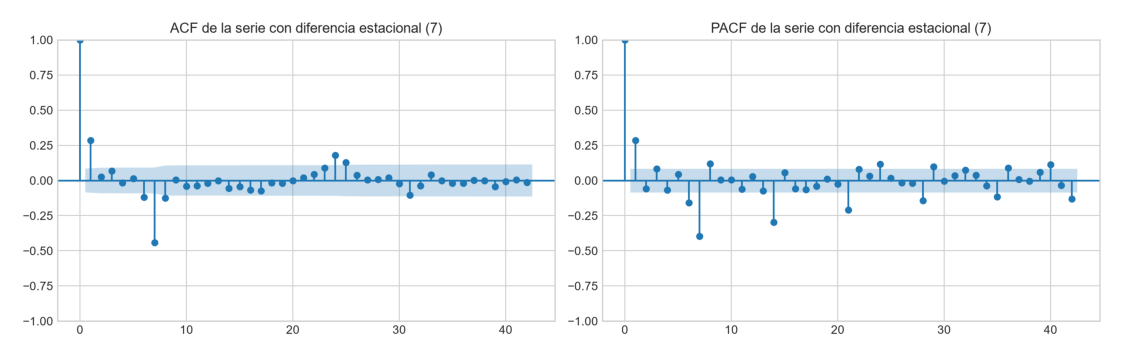

Grilla de órdenes (mejores por BIC):


,orden,AIC,BIC,LjungBox_p7,LjungBox_p14
0,"(2,0,1)x(0,1,1,7)",306.6,362.2,0.453,0.466
1,"(1,0,2)x(0,1,1,7)",307.2,362.7,0.296,0.308
2,"(1,0,0)x(0,1,1,7)",317.3,364.3,0.258,0.362
3,"(1,0,2)x(1,1,1,7)",304.5,364.3,0.786,0.684
4,"(2,0,1)x(1,1,1,7)",304.9,364.7,0.809,0.750


In [18]:
figura("fig19_acf_pacf_sarimax.png", ancho=12)
print("Grilla de órdenes (mejores por BIC):")
d = pd.read_csv(TAB / "tabla_sarimax_grilla.csv"); display(d.head(5))

### 6.3 Resultados con el total AMBA (28 días)

,dias,MAE,RMSE,MAPE_pct,sesgo,MASE
modelo,,,,,,
naive_7,1161.0,0.472,0.824,19.549,-0.052,1.431
naive_364,1161.0,0.395,0.698,17.374,0.076,1.195
sarimax,1161.0,0.270,0.370,11.807,0.005,0.819
prophet,1161.0,0.254,0.375,11.850,-0.002,0.769
gradient_boosting,1161.0,0.187,0.267,7.433,0.019,0.568


Diebold-Mariano: diferencia de MAE de cada modelo contra el Gradient Boosting (positiva = peor que él)


,modelo,contra,dif_MAE,error_std_HAC,p_valor,dias
0,naive_7,gradient_boosting,0.286,0.031,0.0,1161
2,naive_364,gradient_boosting,0.208,0.021,0.0,1161
4,sarimax,gradient_boosting,0.083,0.010,0.0,1161
6,sarimax_sin_anual,gradient_boosting,0.131,0.019,0.0,1161
8,sarimax_orden_original,gradient_boosting,0.081,0.009,0.0,1161
10,prophet,gradient_boosting,0.067,0.008,0.0,1161
13,sarimax_en_logs,gradient_boosting,0.057,0.009,0.0,1161
15,gb_solo_calendario,gradient_boosting,0.050,0.009,0.0,1161


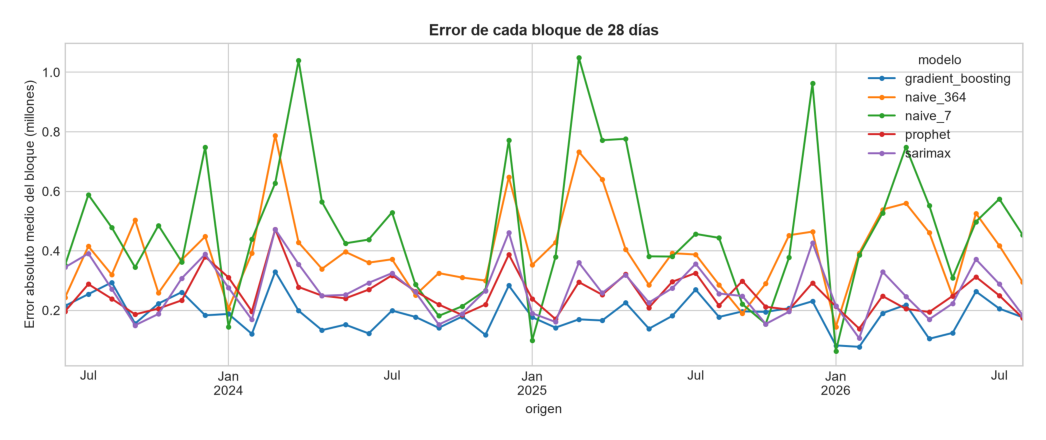

In [19]:
orden = ["naive_7", "naive_364", "sarimax", "prophet", "gradient_boosting"]
g = pd.read_csv(TAB / "tabla_p2_metricas_globales.csv")
g = g[(g.muestra == "sin atípicos") & g.modelo.isin(orden)].set_index("modelo").loc[orden, ["dias", "MAE", "RMSE", "MAPE_pct", "sesgo", "MASE"]]
display(g.round(3))
print("Diebold-Mariano: diferencia de MAE de cada modelo contra el Gradient Boosting (positiva = peor que él)")
dm = pd.read_csv(TAB / "tabla_p2_diebold_mariano.csv"); display(dm[(dm.contra == "gradient_boosting")].round(4))
figura("fig21_p2_error_por_corte.png", ancho=11)

**Lectura.** El Gradient Boosting es el mejor método para el total (MAPE 7,4%, MASE 0,57) y supera a todos los demás con p < 0,0001. Se sostiene en los cuatro períodos evaluados (jul–dic 2023, 2024, 2025 y 2026) y en los cuatro tramos de horizonte dentro de los 28 días.

### 6.4 Por qué: dónde está el error

tipo_dia,domingo,feriado,hábil,sábado
modelo,,,,
naive_7,0.141,1.730,0.501,0.183
naive_364,0.186,1.635,0.370,0.249
sarimax,0.253,0.674,0.255,0.206
prophet,0.252,0.884,0.213,0.215
gradient_boosting,0.131,0.284,0.198,0.151


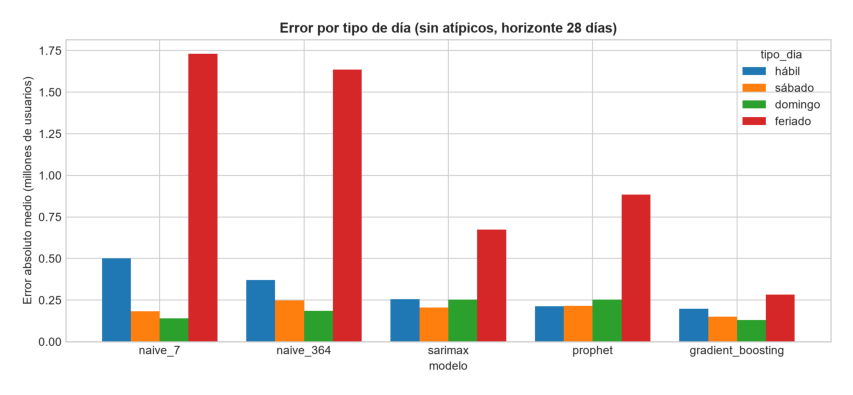

In [20]:
t = pd.read_csv(TAB / "tabla_p2_metricas_por_tipo_dia.csv")
display(t[t.modelo.isin(orden)].pivot(index="modelo", columns="tipo_dia", values="MAE").loc[orden].round(3))
figura("fig20_p2_error_por_tipo_dia.png", ancho=9)

Para entender el *por qué* se compararon variantes (ablaciones), cambiando una cosa por vez:

| Hallazgo | Evidencia (MAE, millones) |
|---|---|
| **Los feriados explican el grueso de la ventaja sobre los Naive.** Un Naive repite la semana anterior y falla cuando cae un feriado. | Feriados: Naive 7 = 1,73; Gradient Boosting = 0,28; SARIMAX = 0,67 |
| **La estacionalidad anual importa.** | SARIMAX sin término anual 0,318 contra 0,270 con él |
| **El patrón semanal es multiplicativo.** En logaritmos el SARIMAX mejora 10%. | SARIMAX en logs 0,243 contra 0,270; domingos 0,132 contra 0,253 |
| **El Gradient Boosting gana por el calendario y por los rezagos.** Solo con calendario ya supera a SARIMAX y Prophet; los rezagos suman otro 21%. | Solo calendario 0,237; completo 0,187 |
| **Identificar el orden del SARIMAX no cambió el resultado.** | Identificado 0,270; orden original del repositorio 0,268 |

En sábados y domingos el Naive de 7 días es competitivo (el patrón de fin de semana es estable); las ganancias de los modelos vienen de los **días hábiles y los feriados**.

### 6.5 Por modo: ¿gana el mismo método?

modo,colectivo_amba,subte_amba,tren_amba
modelo,,,
gradient_boosting,0.588,0.713,0.617
naive_364,1.191,1.861,1.317
naive_7,1.429,1.278,1.245
prophet,0.785,0.913,0.645
sarimax,0.830,0.749,0.624
sarimax_en_logs,0.752,0.898,0.722


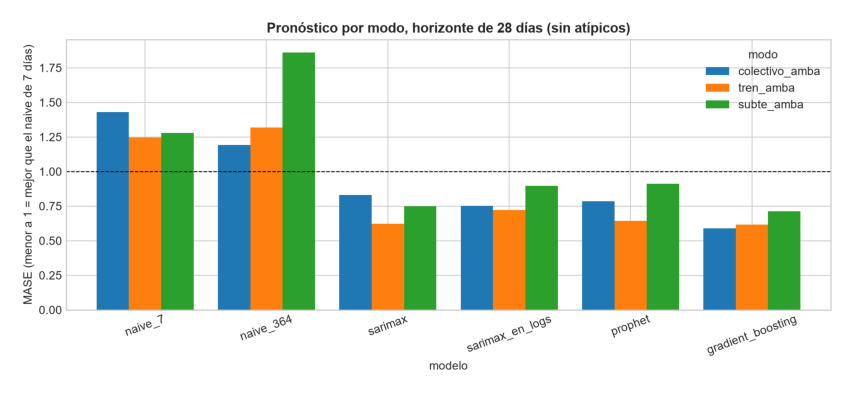

In [21]:
m = pd.read_csv(TAB / "tabla_p2_modo_metricas.csv")
display(m.pivot(index="modelo", columns="modo", values="MASE").round(3))
figura("fig22_p2_mase_por_modo.png", ancho=9)

**Lectura.** En el **colectivo** (90% de los usuarios) gana el Gradient Boosting con claridad. En **tren y subte** el Gradient Boosting y el SARIMAX **empatan** (Diebold-Mariano: p = 0,82 y 0,53). Que el Gradient Boosting sea el mejor para el total viene sobre todo del colectivo.

Además se ve una complementariedad: en días hábiles los modelos aditivos le ganan al Gradient Boosting en tren y subte; en feriados y fines de semana ocurre lo contrario. Eso lleva a probar un híbrido.

### 6.6 Híbrido por tipo de día
Un modelo que use cada método donde rinde mejor. Se probaron tres versiones, todas con los pronósticos ya calculados:
- **Híbrido fijo:** SARIMAX en días hábiles, Gradient Boosting en el resto. La regla surge de mirar toda la muestra de prueba, así que es una cota optimista.
- **Híbrido walk-forward:** en cada corte elige, para cada tipo de día, el método con menor error en los cortes **anteriores** (sin mirar el futuro). Es la versión honesta.
- **Promedio** simple de SARIMAX y Gradient Boosting.

serie,total_amba,colectivo_amba,tren_amba,subte_amba
modelo,,,,
sarimax,0.819,0.830,0.624,0.749
prophet,0.769,0.785,0.645,0.913
gradient_boosting,0.568,0.588,0.617,0.713
hibrido_fijo,0.683,0.693,0.547,0.602
hibrido_walkforward,0.580,0.605,0.536,0.612
promedio_sarimax_gb,0.618,0.637,0.552,0.632


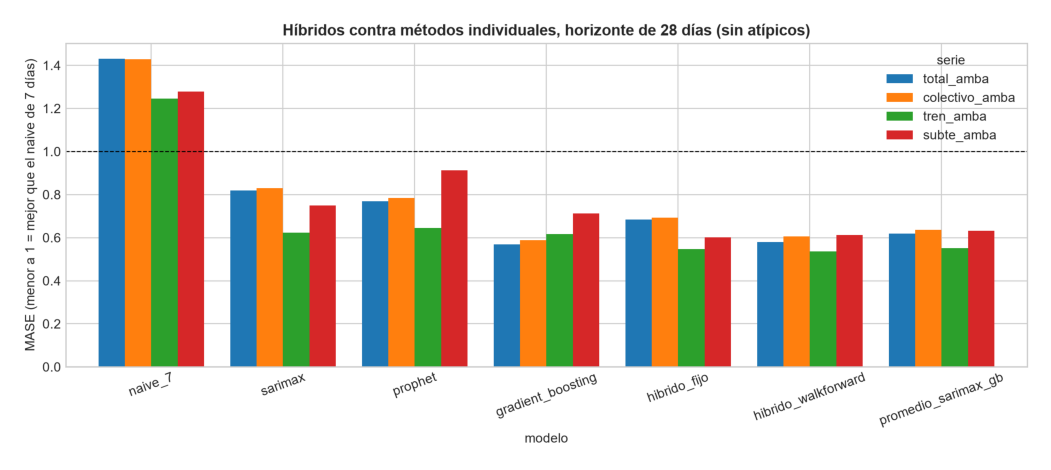

In [22]:
h = pd.read_csv(TAB / "tabla_p2_hibrido_metricas.csv")
ordh = ["sarimax", "prophet", "gradient_boosting", "hibrido_fijo", "hibrido_walkforward", "promedio_sarimax_gb"]
display(h.pivot(index="modelo", columns="serie", values="MASE").loc[ordh][["total_amba", "colectivo_amba", "tren_amba", "subte_amba"]].round(3))
figura("fig23_p2_hibrido.png", ancho=11)

**Lectura.** En **tren y subte** el híbrido mejora a los dos métodos de origen (MASE de 0,62 a 0,54 en el tren y de 0,71 a 0,61 en el subte; p < 0,01); el promedio simple ya mejora a ambos, así que la ganancia viene de que sus errores se complementan. En **total y colectivo** no aporta, porque el Gradient Boosting gana también en días hábiles. **Respuesta a P-2:** no hay un método único; el mejor depende de la serie y del tipo de día.

*Límite:* la idea del híbrido surgió de mirar los mismos resultados y se hicieron 24 comparaciones; se presenta como hallazgo a confirmar en otro período.

### 6.7 Robustez: huecos y horizonte
**Tratamiento de los días sin dato.** Se reentrenó con los 62 días interpolados y con los 62 días vacíos.

variante,faltantes,interpolada,reconstruida
modelo,,,
gradient_boosting,0.606,0.630,0.562
prophet,0.805,0.798,0.764
sarimax,0.808,0.824,0.806


Horizontes de 7, 28 y 90 días (MASE):


horizonte,7.0,28.0,90.0
modelo,,,
naive_7,1.190,1.431,1.436
naive_364,1.191,1.195,1.208
sarimax,0.773,0.819,0.851
prophet,0.759,0.769,0.776
gradient_boosting,0.559,0.568,0.612


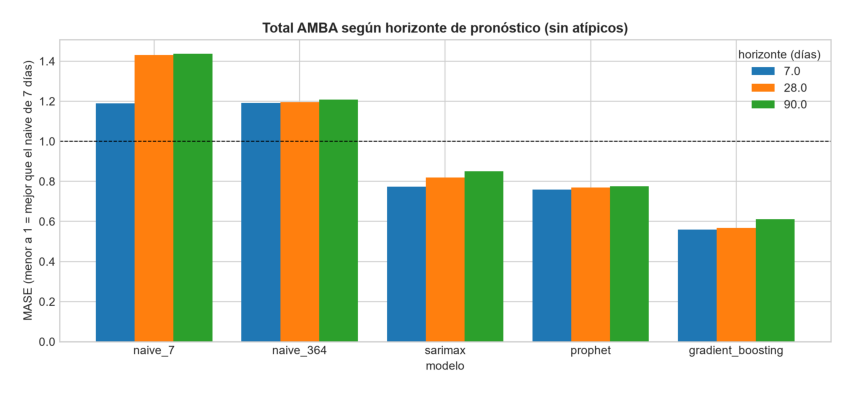

In [23]:
hu = pd.read_csv(TAB / "tabla_p2_huecos_metricas.csv")
hu = hu[hu.muestra == "sin atípicos ni días reconstruidos"]
display(hu.pivot(index="modelo", columns="variante", values="MASE").round(3))
print("Horizontes de 7, 28 y 90 días (MASE):")
ho = pd.read_csv(TAB / "tabla_p2_horizontes_metricas.csv")
display(ho.pivot(index="modelo", columns="horizonte", values="MASE").loc[orden].round(3))
figura("fig24_p2_horizontes.png", ancho=9)

**Lectura.** El **ranking no depende** de cómo se traten los huecos ni del horizonte: el Gradient Boosting gana en todos los casos. La reconstrucción desde transacciones sí mejora el nivel de error del Gradient Boosting (MASE 0,56 contra 0,63 con interpolación). El error crece poco con el horizonte (Gradient Boosting: 0,56 a 7 días, 0,57 a 28 y 0,61 a 90), porque la mayor parte del error viene de los feriados, que se conocen con anticipación. Con los días vacíos, el SARIMAX del primer corte divergió numéricamente; se excluyó ese corte de todas las variantes para comparar los mismos días.

### 6.8 Intervalos de predicción
Los intervalos salen de los errores de los cortes anteriores en el mismo horizonte (método conforme). La cobertura observada es cercana a la nominal: entre 79% y 85% para el 80% y entre 94% y 95% para el 95%. Un modelo mejor da intervalos más estrechos con la misma cobertura.

In [24]:
tabla("tabla_p2_intervalos")

,modelo,dias,cobertura_80,semiancho_80,cobertura_95,semiancho_95
0,naive_7,952,0.807,0.720,0.937,2.332
1,naive_364,952,0.785,0.453,0.940,1.955
2,sarimax,952,0.821,0.426,0.945,0.830
3,prophet,952,0.809,0.344,0.949,0.848
4,gradient_boosting,952,0.847,0.314,0.942,0.568


### 6.9 Pronóstico de los hitos de P-1: feriados, paros, elecciones y saltos tarifarios
Las comparaciones anteriores excluyen los paros y las elecciones. Pero para planificar importa justamente lo contrario: **qué pasa con la demanda si hay un paro, una elección o un aumento de tarifa**, y qué método se equivoca menos. Acá se evalúan los mismos pronósticos (origen móvil, 28 días) en los días de los hitos de P-1, sin darles información adicional: los modelos conocen solo el pasado y el calendario de feriados.

Se miden tres cosas:

- **A. Error en días de hito**, por método: MAE (millones de usuarios) para el total del AMBA.
- **B. Pronóstico condicional (escenario).** Si se *sabe* que habrá un paro o una elección, el pronóstico del método puede multiplicarse por el cociente típico que midió P-1 para ese tipo de día y ese modo (mediana de los **otros** días del mismo grupo, dejando afuera el día evaluado). Es lo que haría un planificador que conoce el calendario de paros y elecciones. Hay pocos eventos por grupo (de 3 a 6), así que es una ilustración y no una prueba.
- **C. Saltos tarifarios.** Pronósticos hechos **el día anterior** al primer aumento del salto (el origen móvil de 28 días no sirve para esto, porque casi siempre incorpora parte del aumento), y su error en los 28 días hábiles posteriores al último aumento. Se compara con el error habitual del mismo método a horizontes largos, y con un pronóstico que además recibe el precio: el del método multiplicado por exp(ε × cambio en log de la tarifa real), con la elasticidad ε de P-1 para ese modo (−0,012 colectivo, −0,043 tren, −0,224 subte). Como esa elasticidad se estimó con toda la muestra, este último resultado es **optimista**.

modelo,naive_7,naive_364,sarimax,prophet,gradient_boosting
grupo,,,,,
día hábil ordinario,0.501,0.370,0.255,0.213,0.198
feriado laborable,2.024,1.909,0.507,0.732,0.298
paro (cualquier modo),2.085,2.069,2.072,2.060,2.094
elección con gratuidad,1.368,1.260,1.275,1.510,1.300
elección sin gratuidad,0.189,0.412,0.546,0.427,0.323


Por modo (MAE, millones):


modelo                            naive_7  naive_364  sarimax  prophet  gradient_boosting
modo      grupo                                                                          
colectivo día hábil ordinario       0.471      0.347    0.244    0.207              0.195
          elección con gratuidad    1.274      1.165    1.196    1.410              1.229
          elección sin gratuidad    0.197      0.404    0.531    0.441              0.318
          feriado laborable         1.882      1.764    0.480    0.682              0.289
          paro: modo que no paró    0.865      0.926    0.872    0.834              0.725
          paro: modo que paró       2.630      2.708    2.612    2.606              2.732
subte     día hábil ordinario       0.051      0.080    0.028    0.029              0.033
          elección con gratuidad    0.158      0.158    0.154    0.174              0.160
          elección sin gratuidad    0.004      0.026    0.043    0.049              0.007
          feriado laborable         0.226      0.255    0.046    0.088              0.031
          paro: modo que no paró    0.035      0.103    0.035    0.056              0.044
          paro: modo que paró       0.334      0.412    0.361    0.351              0.355
tren      día hábil ordinario       0.082      0.086    0.037    0.035              0.044
          elección con gratuidad    0.180      0.177    0.172    0.202              0.171
          elección sin gratuidad    0.025      0.058    0.082    0.039              0.037
          feriado laborable         0.411      0.400    0.094    0.142              0.072
          paro: modo que no paró    0.240      0.232    0.202    0.190              0.255
          paro: modo que paró       0.602      0.603    0.604    0.598              0.616

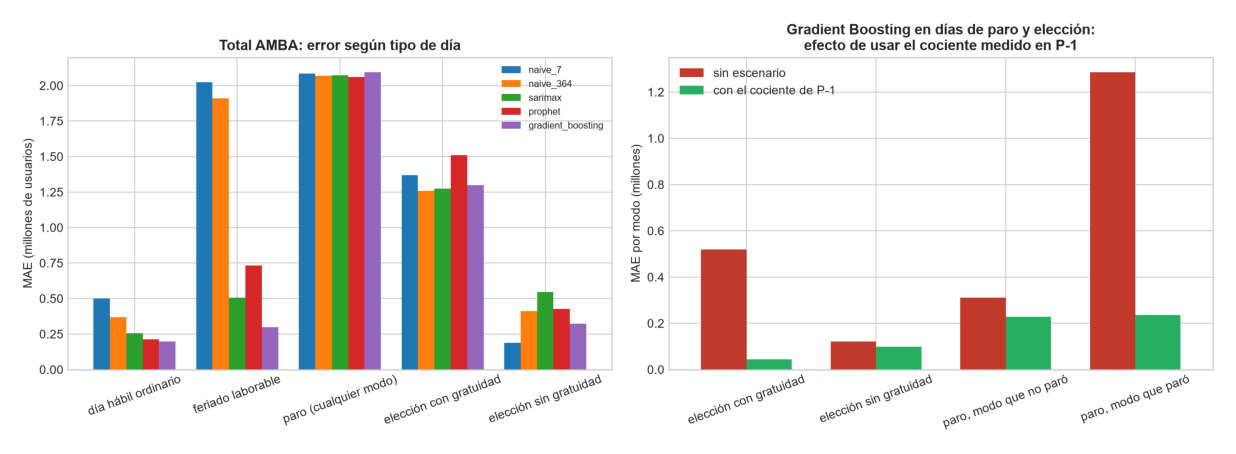

In [25]:
orden = ["naive_7", "naive_364", "sarimax", "prophet", "gradient_boosting"]
e = pd.read_csv(TAB / "tabla_p2_hitos_errores.csv")
tot = e[e.modo == "total"].pivot(index="grupo", columns="modelo", values="MAE")[orden]
display(tot.loc[["día hábil ordinario", "feriado laborable", "paro (cualquier modo)", "elección con gratuidad", "elección sin gratuidad"]].round(3))
print("Por modo (MAE, millones):")
display(e[e.modo != "total"].pivot_table(index=["modo", "grupo"], columns="modelo", values="MAE")[orden].round(3))
figura("fig27_p2_hitos.png", ancho=13)

**Lectura de A.**

- **Feriados laborables: se anticipan, y el método importa.** Los métodos que conocen el calendario (Gradient Boosting y SARIMAX) tienen un MAE de 0,30 y 0,51 millones, contra 1,9 a 2,0 de los Naive, que repiten un día normal. El Gradient Boosting reduce el error 85% respecto del Naive de 7 días. Es el resultado de P-2 que más se traslada a un hito: los feriados son predecibles porque el calendario se conoce.
- **Paros: ningún método los anticipa.** El MAE es de 2,06 a 2,09 millones para los cinco métodos, es decir, casi toda la demanda de un día hábil normal que desaparece. Da igual qué método se elija.
- **Elecciones con gratuidad: tampoco.** El error es de 1,26 a 1,51 millones, y es peor en Prophet; ninguno se acerca al de un día ordinario (0,20 a 0,50).
- **Elecciones sin gratuidad (2025):** el mejor es el Naive de 7 días (0,19), porque esos domingos se parecen a un domingo normal; los métodos con estacionalidad anual se equivocan más (0,32 a 0,55). Son tres eventos.

In [26]:
b = pd.read_csv(TAB / "tabla_p2_hitos_escenario.csv")
g = b.groupby(["grupo", "modelo"]).apply(lambda x: pd.Series({"MAE sin escenario": (x.MAE_base * x.dias).sum() / x.dias.sum(),
                                                               "MAE con escenario": (x.MAE_escenario * x.dias).sum() / x.dias.sum()}))
g["reducción %"] = (1 - g["MAE con escenario"] / g["MAE sin escenario"]) * 100
display(g.round(3))

MAE sin escenario  MAE con escenario  reducción %
grupo                  modelo                                                              
elección con gratuidad gradient_boosting              0.520              0.043       91.667
                       naive_364                      0.500              0.046       90.800
                       naive_7                        0.537              0.042       92.122
                       prophet                        0.595              0.038       93.617
                       sarimax                        0.507              0.045       91.196
elección sin gratuidad gradient_boosting              0.121              0.098       18.508
                       naive_364                      0.163              0.126       22.541
                       naive_7                        0.075              0.080       -6.637
                       prophet                        0.176              0.115       34.972
                       sarimax                        0.219              0.148       32.317
paro, modo que no paró gradient_boosting              0.312              0.229       26.412
                       naive_364                      0.389              0.320       17.679
                       naive_7                        0.346              0.266       22.865
                       prophet                        0.330              0.190       42.263
                       sarimax                        0.336              0.221       34.146
paro, modo que paró    gradient_boosting              1.286              0.236       81.668
                       naive_364                      1.290              0.239       81.447
                       naive_7                        1.239              0.235       81.027
                       prophet                        1.234              0.235       80.981
                       sarimax                        1.241              0.232       81.347

**Lectura de B.** Conocer el evento y su efecto típico importa **mucho más que el método**:

- En el **modo que para**, multiplicar el pronóstico por el cociente típico de P-1 reduce el error de **81% a 82%** con los cinco métodos, y los cinco quedan con un MAE casi idéntico (0,23 a 0,24 millones por modo y día, contra 1,2 a 1,3 sin escenario).
- En las **elecciones con gratuidad** la reducción es de **91% a 94%** (el MAE por modo pasa de 0,5–0,6 a 0,04).
- En los modos **que no pararon**, la mejora es de 18% a 42%, según el método (el cociente típico del tren cuando para el colectivo es 0,67, y el del subte cercano a 1).
- En las **elecciones sin gratuidad** el escenario ayuda poco (de −7% a +35%) y empeora al Naive de 7 días: no hay un efecto uniforme que aplicar.

Es decir: para paros y elecciones gratuitas **la elección del método es secundaria**; lo que mejora el pronóstico es **saber que el evento ocurre y cuánto reduce la demanda** (justamente lo que mide P-1). Estos eventos suelen anunciarse con anticipación (los paros, días antes; el calendario electoral, meses), de modo que el escenario es operativo. Límites: el cociente se estima con los demás eventos del mismo grupo, que son pocos (de 3 a 6), con adhesión variable entre paros; y la intensidad de un paro con adhesión parcial no se conoce de antemano.

In [27]:
c = pd.read_csv(TAB / "tabla_p2_hitos_tarifas.csv")
gb = c[c.modelo == "gradient_boosting"].drop(columns="modelo")
print("Gradient Boosting, pronóstico hecho el día anterior al salto (sobreestimación = pronóstico menos real, en % del real):")
display(gb)
res = pd.read_csv(TAB / "tabla_p2_hitos_tarifas_resumen.csv")
res["tipo de salto"] = res.grande.map({True: "grande (×3 o más)", False: "moderado"})
print("Promedio por tipo de salto y método:")
display(res.drop(columns="grande").set_index(["tipo de salto", "modelo"]).round(2))

Gradient Boosting, pronóstico hecho el día anterior al salto (sobreestimación = pronóstico menos real, en % del real):


,modo,salto_desde,tarifa_x,cambio_demanda_pct_P1,dias_ventana,sobreestimacion_pct,sobreestimacion_pct_habitual,MAPE,MAPE_habitual,sobreestimacion_pct_con_precio,MAPE_con_precio
0,colectivo,2024-01-15,3.93,-13.3,17,2.63,0.79,3.96,5.67,0.82,3.66
5,colectivo,2024-08-12,1.32,-1.3,20,-4.00,0.79,6.39,5.67,-4.35,6.62
10,colectivo,2026-02-18,1.38,9.0,19,-2.88,0.79,4.87,5.67,-3.18,4.96
15,subte,2024-05-17,4.21,-19.4,17,14.24,4.88,14.24,11.99,-20.24,20.24
20,subte,2024-10-01,1.14,-10.4,19,10.50,4.88,10.89,11.99,7.43,8.49
25,tren,2024-01-15,3.18,1.4,17,-6.22,2.41,7.46,7.81,-11.02,11.46
30,tren,2024-05-06,1.34,-14.7,19,5.09,2.41,6.28,7.81,3.17,5.27
35,tren,2024-09-16,1.40,1.0,19,2.25,2.41,3.93,7.81,0.83,4.02
40,tren,2026-05-18,1.32,-0.1,19,1.51,2.41,5.20,7.81,0.62,5.14


Promedio por tipo de salto y método:


sobreestimacion_pct  sobreestimacion_pct_habitual   MAPE  MAPE_habitual  MAPE_con_precio
tipo de salto     modelo                                                                                                     
moderado          gradient_boosting                 2.08                          2.28   6.26           7.79             5.75
                  naive_364                         4.15                          2.63  14.78          14.18            13.67
                  naive_7                          -5.72                         -3.04  12.88          14.78            12.63
                  prophet                           1.25                          0.98   5.21           6.06             4.75
                  sarimax                           0.17                          1.78   6.16           7.16             5.83
grande (×3 o más) gradient_boosting                 3.55                          2.69   8.55           8.49            11.79
                  naive_364                        -2.18                          4.64  14.41          15.85            17.31
                  naive_7                           6.46                         -2.67  10.81          15.38             9.64
                  prophet                           6.31                          1.67   7.29           6.69            12.34
                  sarimax                           5.26                          2.27   8.03           7.77            12.44

**Lectura de C.** `sobreestimacion_pct` es el sesgo medio del pronóstico en los 28 días hábiles posteriores al último aumento (positivo = el modelo esperaba más demanda de la que hubo); `sobreestimacion_pct_habitual` y `MAPE_habitual` son los del mismo método y modo a horizontes de 22 a 28 días en el resto de la muestra; `*_con_precio` son los del pronóstico que recibe el precio.

- **Moderados (+10% a +40%).** El error no se distingue del habitual: el MAPE del Gradient Boosting va de 3,9% a 6,4% en el colectivo y el tren (habituales: 5,7% y 7,8%) y es de 10,9% en el subte (habitual: 12%). Los modelos no son "sorprendidos" por los saltos chicos.
- **Grandes.** El **subte de mayo de 2024 (tarifa ×4)** es el único caso donde el modelo sin precio sobreestima claramente: **+14%** contra un sesgo habitual de +5% (la caída medida en P-1 es de −19%). El **colectivo de enero–febrero de 2024** apenas se desvía (+2,6%, contra +0,8% habitual) y el **tren de enero de 2024** se equivoca en el sentido contrario (−6%, es decir, la demanda fue *mayor* que la pronosticada), coherente con que P-1 no encuentra una caída del tren en ese salto.
- **Incorporar el precio.** Para los saltos **moderados**, el pronóstico con precio mejora levemente (MAPE del Gradient Boosting de 6,3% a 5,8%; de 5,2% a 4,8% en Prophet). Para los **grandes** empeora (de 8,6% a 11,8% con Gradient Boosting): al subte de mayo de 2024 le aplica una elasticidad de −0,22 a un aumento real de ×4,4 y sobrecorrige (−20%, la demanda pronosticada queda por debajo de la real), y al tren de enero de 2024 le resta 11% a una demanda que no cayó. Una elasticidad constante estimada con saltos chicos no extrapola bien a un aumento que multiplica la tarifa por cuatro.
- **Conclusión.** Con la información disponible (pocos saltos, tres de ellos grandes y de 2024) no se puede afirmar que un modelo con precio pronostique mejor el efecto de un aumento. Los saltos moderados no requieren un tratamiento especial; los grandes son tan raros y tan distintos del resto de la historia que un modelo de pronóstico no tiene de dónde aprender su efecto. Para responder "qué pasa si se sube la tarifa X%" sirve más un escenario de P-1 (con su intervalo de incertidumbre) que un modelo de series temporales ajustado con datos históricos.

## 7. Discusión y conclusiones

**P-1.** El precio importa para el **subte** (elasticidad de −0,15 a −0,26 según se controle o no por el salario real; para dar una referencia, la literatura internacional reporta valores de corto plazo del orden de −0,3) y casi nada para el **colectivo nacional** y el **tren** en los saltos tarifarios observados. Los efectos más claros y estables son los de **calendario**: un feriado laborable, un paro propio o una elección con gratuidad reducen la demanda a una fracción de un día normal, mucho más que cualquier salto de tarifa. No hay evidencia de sustitución entre modos ni de que las líneas de mayor ingreso reaccionen menos (aunque esta última prueba tiene poco poder). Los resultados del precio **no son un efecto causal demostrado**: los diseños usados (control del año anterior, control sintético, control por salario real) absorben lo común pero dependen de supuestos, y Granger es solo evidencia predictiva. En los paros, el modo que para cae a casi cero y los otros **no absorben esa demanda**: el subte no sube cuando para el colectivo y el tren cae (complementariedad).

**P-2.** El **Gradient Boosting** es el mejor método para el total y el colectivo, y la razón principal es cómo trata el calendario (feriados, patrón semanal multiplicativo, estacionalidad anual) y, en segundo lugar, los rezagos. Para tren y subte hay empate con el SARIMAX y un **híbrido por tipo de día** mejora a ambos. El resultado es robusto al tratamiento de los huecos y al horizonte. Para los hitos de P-1, los feriados se anticipan con el calendario (el Gradient Boosting reduce 85% el error del Naive), los paros y las elecciones gratuitas no se anticipan con ningún método, y lo que mejora el pronóstico en esos días es **conocer el evento y su efecto típico** (reducción de 81% a 94% del error), no el método.

**Un mismo dato, dos enfoques.** Para *predecir* conviene el método más flexible, aunque sea una caja negra; para *atribuir* un efecto hace falta un diseño con contrafactual y supuestos explícitos. El Gradient Boosting pronostica bien pero no dice cuánto se debe al precio; las herramientas de P-1 sí intentan aislar ese efecto, con menos precisión.

**Limitaciones.**
- Los modelos usan configuración estándar sin ajuste fino de hiperparámetros.
- Los paros y las elecciones no se pronostican y se excluyen de las métricas; en esos días el error es mucho mayor.
- La demanda del subte desde 2025 es de 18% a 30% menor que la que informa el CEPA; no se resolvió y se trata como limitación.
- Las tarifas de varias jurisdicciones son parcialmente inferidas (cada fila indica su fuente).
- Octubre de 2026 es preliminar y no se evalúa.
- El híbrido es un hallazgo exploratorio a confirmar en otro período.
- Los resultados sobre hitos de P-2 (paros, elecciones y saltos tarifarios) se basan en pocos eventos por grupo; los cocientes de P-1 usados como escenario se estiman con los demás eventos del mismo grupo.
- El RIPTE es un salario formal, nacional y mensual; no representa el ingreso de todos los usuarios.

**Trabajo futuro.** Probar el híbrido con datos nuevos; ajustar hiperparámetros del Gradient Boosting y del SARIMAX; explorar modelos de aprendizaje profundo para el pronóstico.

## 8. Reproducibilidad y referencias

El orden de ejecución de los scripts está en el `README.md`. Todos los resultados que muestra este notebook se generan con los scripts de `scripts/` y quedan en `resultados/tablas` y `resultados/figuras`.

**Referencias**
1. Box, G. E., Jenkins, G. M., Reinsel, G. C., & Ljung, G. M. (2015). *Time series analysis: forecasting and control*. Wiley.
2. Hyndman, R. J., & Athanasopoulos, G. (2018). *Forecasting: principles and practice*. OTexts.
3. Cleveland, R. B., Cleveland, W. S., McRae, J. E., & Terpenning, I. (1990). STL: A seasonal-trend decomposition procedure based on loess. *Journal of Official Statistics*, 6(1), 3-73.
4. Taylor, S. J., & Letham, B. (2018). Forecasting at scale. *The American Statistician*, 72(1), 37-45.
5. Dickey, D. A., & Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *JASA*, 74(366a), 427-431.
6. Kwiatkowski, D., Phillips, P. C., Schmidt, P., & Shin, Y. (1992). Testing the null hypothesis of stationarity against the alternative of a unit root. *Journal of Econometrics*, 54(1-3), 159-178.
7. Granger, C. W. J. (1969). Investigating causal relations by econometric models and cross-spectral methods. *Econometrica*, 37(3), 424-438.
8. Abadie, A., Diamond, A., & Hainmueller, J. (2010). Synthetic control methods for comparative case studies. *JASA*, 105(490), 493-505.
9. Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253-263.
10. Hyndman, R. J., & Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting*, 22(4), 679-688.
11. Balcombe, R., Mackett, R., Paulley, N., Preston, J., Shires, J., Titheridge, H., Wardman, M., & White, P. (2004). *The demand for public transport: a practical guide* (TRL Report TRL593). TRL Limited.